In [1]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["NUMBA_NUM_THREADS"] = "1"

In [2]:
from __future__ import annotations

import soundfile as sf
import numpy as np
import sys
from pathlib import Path
from scipy.stats import kurtosis, skew
from scipy.io import wavfile
import math
from scipy import signal

ROOT = Path().resolve().parent
sys.path.insert(0, str(ROOT))
from multiprocessing import Value, Lock

In [3]:
import wave
import scipy.io.wavfile as wav
import matplotlib.pyplot as plt
from numpy.lib import stride_tricks
from scipy.io import wavfile
from pydub import AudioSegment
from pystoi import stoi as pystoi_stoi
from pesq import pesq as pesq_metric
import csv
from pathlib import Path
from joblib import Parallel, delayed
from multiprocessing import Manager

In [4]:
import importlib
import algoss.alg1_sim.script1
importlib.reload(algoss.alg1_sim.script1)
import algoss.alg2_wavelet.script_wavelet
importlib.reload(algoss.alg2_wavelet.script_wavelet)
# import alg4.script4
# importlib.reload(alg4.script4)
import algoss.alg3_lossless.script_lossless
importlib.reload(algoss.alg3_lossless.script_lossless)
import algoss.alg5_emd.emd_v3
importlib.reload(algoss.alg5_emd.emd_v3)
import algoss.alg6_wht.wht_v3
importlib.reload(algoss.alg6_wht.wht_v3)
# import alg5_emd.emd_v3
# importlib.reload(alg5_emd.emd_v3)
# import alg6_wht.wht_v3
# importlib.reload(alg6_wht.wht_v3)
import algoss.alg7_kra.kra_v1
importlib.reload(algoss.alg7_kra.kra_v1)
import algoss.alg7_kra.test_realtime
importlib.reload(algoss.alg7_kra.test_realtime)

<module 'algoss.alg7_kra.test_realtime' from '/home/cossie/nears/test_stand/algoss/alg7_kra/test_realtime.py'>

In [5]:
import numpy as np
import algoss.alg7_kra.test_realtime as alg7

print("BEFORE:", alg7.my_ps.c_0.shape, alg7.my_ps.u_0.shape)

alg7.my_ps.c_0 = np.asarray(
    alg7.my_ps.c_0, dtype=np.float64
).reshape(-1)

alg7.my_ps.u_0 = np.asarray(
    alg7.my_ps.u_0, dtype=np.float64
).reshape(-1)

print("AFTER:", alg7.my_ps.c_0.shape, alg7.my_ps.u_0.shape)

assert alg7.my_ps.c_0.shape == (8,)
assert alg7.my_ps.u_0.shape == (16,)

BEFORE: (8,) (16,)
AFTER: (8,) (16,)


In [6]:
# with wave.open("input.wav", "rb") as w:
#     nch = w.getnchannels()     # каналы
#     sampwidth = w.getsampwidth()  # байт на 1 отсчёт В ОДНОМ КАНАЛЕ
#     rate = w.getframerate()
#     nframes = w.getnframes()

# print("channels =", nch)
# print("bytes per sample (per channel) =", sampwidth)
# print("bits per sample =", sampwidth * 8)
# print("bytes per frame (all channels) =", sampwidth * nch)  # один момент времени
# print("frames =", nframes)

# Загрузка данных

In [7]:
def load_wav(path: str, *, mono: bool = True, dtype="float32"):
    x, sr = sf.read(path, dtype=dtype, always_2d=True)  # shape: (N, C)
    if mono:
        x = x.mean(axis=1)  # (N,)
    else:
        x = x.T  # (C, N) если нужно поканально
    return x, sr

def load_wav_bytes(path: str) -> tuple[int, np.ndarray]:
    fs, data = wavfile.read(path)
    if data.dtype.kind == "f":
        m = np.max(np.abs(data))
        if m > 0:
            data = data / m
        data = (data * 32767.0).astype(np.int16)
    elif data.dtype == np.int32:
        data = (data >> 16).astype(np.int16)
    elif data.dtype == np.uint8:
        data = ((data.astype(np.int16) - 128) << 8).astype(np.int16)
    else:
        data = data.astype(np.int16)
    raw = np.frombuffer(data.tobytes(), dtype=np.uint8)
    return fs, raw

def save_wav_bytes(bytes_: tuple[int, np.ndarray], path: str):
    fs, raw = bytes_
    samples = np.frombuffer(raw.tobytes(), dtype=np.int16)
    wavfile.write(path, fs, samples)

## Энтропия

In [8]:
def entropy_normalized(path):
    path = str(path)
    with wave.open(path, "rb") as w:
        data = w.readframes(w.getnframes())
    data = np.frombuffer(data, dtype=np.uint8)
    hist = np.bincount(data, minlength=256)
    p = hist / hist.sum()
    p = p[p>0]
    return -np.sum(p * np.log2(p))

## Корреляция

In [9]:
def correlatioin(first, second):
    first = str(first)
    second = str(second)
    with wave.open(first, "rb") as w:
        first_bytes = w.readframes(w.getnframes())
    with wave.open(second, "rb") as w:
        second_bytes = w.readframes(w.getnframes())
    first = np.frombuffer(first_bytes, dtype=np.uint8).astype(np.float64)
    second = np.frombuffer(second_bytes, dtype=np.uint8).astype(np.float64)
    n = min(first.size, second.size)
    first = first[:n]
    second = second[:n]
    first_exp = first.mean()
    second_exp = second.mean()
    cov = np.mean((first - first_exp) * (second - second_exp))
    first_D = np.mean((first - first_exp)**2)
    second_D = np.mean((second - second_exp)**2)
    return float(cov / ( np.sqrt(first_D) * np.sqrt(second_D) ))


## Спектрограмма

In [10]:
def stft(sig, frameSize, overlapFac=0.5, window=np.hanning):
    win = window(frameSize)
    hopSize = int(frameSize - np.floor(overlapFac * frameSize))

    # zeros at beginning (thus center of 1st window should be for sample nr. 0)   
    samples = np.append(np.zeros(int(np.floor(frameSize/2.0))), sig)    
    # cols for windowing
    cols = np.ceil( (len(samples) - frameSize) / float(hopSize)) + 1
    # zeros at end (thus samples can be fully covered by frames)
    samples = np.append(samples, np.zeros(frameSize))

    frames = stride_tricks.as_strided(samples, shape=(int(cols), frameSize), strides=(samples.strides[0]*hopSize, samples.strides[0])).copy()
    frames *= win

    return np.fft.rfft(frames) 


def logscale_spec(spec, sr=44100, factor=20.):
    timebins, freqbins = np.shape(spec)

    scale = np.linspace(0, 1, freqbins) ** factor
    scale *= (freqbins-1)/max(scale)
    scale = np.unique(np.round(scale))

    # create spectrogram with new freq bins
    newspec = np.complex128(np.zeros([timebins, len(scale)]))
    for i in range(0, len(scale)):        
        if i == len(scale)-1:
            newspec[:,i] = np.sum(spec[:,int(scale[i]):], axis=1)
        else:        
            newspec[:,i] = np.sum(spec[:,int(scale[i]):int(scale[i+1])], axis=1)

    # list center freq of bins
    allfreqs = np.abs(np.fft.fftfreq(freqbins*2, 1./sr)[:freqbins+1])
    freqs = []
    for i in range(0, len(scale)):
        if i == len(scale)-1:
            freqs += [np.mean(allfreqs[int(scale[i]):])]
        else:
            freqs += [np.mean(allfreqs[int(scale[i]):int(scale[i+1])])]

    return newspec, freqs

def spectogram(audiopath, binsize=2**10, plotpath=None, colormap="jet"): #<------THIS ONEEEEEEEEEE
    samplerate, samples = wav.read(audiopath)

    s = stft(samples, binsize)

    sshow, freq = logscale_spec(s, factor=1.0, sr=samplerate)

    ims = 20.*np.log10(np.abs(sshow)/10e-6) # amplitude to decibel

    timebins, freqbins = np.shape(ims)

    print("timebins: ", timebins)
    print("freqbins: ", freqbins)

    plt.figure(figsize=(6, 3))
    plt.imshow(np.transpose(ims), origin="lower", aspect="auto", cmap=colormap, interpolation="none")
    plt.colorbar()
    
    plt.xlabel("time (s)")
    plt.ylabel("frequency (hz)")
    plt.xlim([0, timebins-1])
    plt.ylim([0, freqbins])

    xlocs = np.float32(np.linspace(0, timebins-1, 5))
    plt.xticks(xlocs, ["%.02f" % l for l in ((xlocs*len(samples)/timebins)+(0.5*binsize))/samplerate])
    ylocs = np.int16(np.round(np.linspace(0, freqbins-1, 10)))
    plt.yticks(ylocs, ["%.02f" % freq[i] for i in ylocs])

    if plotpath:
        plt.savefig(plotpath, bbox_inches="tight")
    else:
        plt.show()

    plt.clf()

## Спектр

In [11]:
def spectr(path):
    myAudio = path
    samplingFreq, mySound = wavfile.read(myAudio)
    mySoundDataType = mySound.dtype
    mySound = mySound / (2.**15)
    mySoundShape = mySound.shape
    samplePoints = float(mySound.shape[0])
    signalDuration =  mySound.shape[0] / samplingFreq
    mySoundOneChannel = mySound[:]
    timeArray = np.arange(0, samplePoints, 1)
    timeArray = timeArray / samplingFreq
    timeArray = timeArray * 1000
    plt.plot(timeArray, mySoundOneChannel, color='b')
    plt.xlabel('Time (ms)')
    plt.ylabel('Amplitude')
    plt.show()

## BER

In [12]:
def get_ber(wav_a: str, wav_b: str) -> float:
    fs1, a = load_wav_bytes(wav_a)
    fs2, b = load_wav_bytes(wav_b)
    if fs1 != fs2:
        raise ValueError(f"Sample rate differs: {fs1} vs {fs2}")
    
    n = min(a.size, b.size)
    if n == 0:
        raise ValueError("Empty audio data")

    a = a[:n]
    b = b[:n]
    x = np.bitwise_xor(a, b)
    diff_bits = np.unpackbits(x).sum()
    total_bits = n*8
    return float(diff_bits) / float(total_bits)

## ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ

In [13]:

def _safe_log10(x: float, eps: float = 1e-12) -> float:
    return math.log10(max(x, eps))

def _frame_signal(x: np.ndarray, frame_len: int, hop_len: int) -> np.ndarray:
    if frame_len <= 0 or hop_len <= 0:
        raise ValueError("frame_len и hop_len должны быть > 0")

    if len(x) < frame_len:
        return np.empty((0, frame_len), dtype=np.float64)

    n_frames = 1 + (len(x) - frame_len) // hop_len
    frames = np.empty((n_frames, frame_len), dtype=np.float64)

    for i in range(n_frames):
        start = i * hop_len
        frames[i] = x[start:start + frame_len]

    return frames

def _magnitude_spectrum(x: np.ndarray, n_fft: int = 1024) -> np.ndarray:
    if len(x) == 0:
        raise ValueError("Пустой сигнал")

    if len(x) < n_fft:
        pad = np.zeros(n_fft - len(x), dtype=np.float64)
        x = np.concatenate([x, pad])

    window = np.hanning(len(x))
    spec = np.fft.rfft(x * window, n=n_fft)
    mag = np.abs(spec)
    return mag

def _power_spectrum(x: np.ndarray, n_fft: int = 1024) -> np.ndarray:
    mag = _magnitude_spectrum(x, n_fft=n_fft)
    return mag ** 2

def _spectral_entropy_from_signal(x: np.ndarray, n_fft: int = 1024, eps: float = 1e-12) -> float:
    p = _power_spectrum(x, n_fft=n_fft)
    p_sum = np.sum(p)
    if p_sum <= eps:
        return 0.0
    p = p / p_sum
    return float(-np.sum(p * np.log2(p + eps)))

def _spectral_flatness_from_signal(x: np.ndarray, n_fft: int = 1024, eps: float = 1e-12) -> float:
    p = _power_spectrum(x, n_fft=n_fft)
    gm = np.exp(np.mean(np.log(p + eps)))
    am = np.mean(p + eps)
    return float(gm / am)


def _spectral_centroid_from_signal(x: np.ndarray, sr: int, n_fft: int = 1024, eps: float = 1e-12) -> float:
    mag = _magnitude_spectrum(x, n_fft=n_fft)
    freqs = np.fft.rfftfreq(n_fft, d=1.0 / sr)
    denom = np.sum(mag)
    if denom <= eps:
        return 0.0
    return float(np.sum(freqs * mag) / denom)

def _spectral_bandwidth_from_signal(x: np.ndarray, sr: int, n_fft: int = 1024, eps: float = 1e-12) -> float:
    mag = _magnitude_spectrum(x, n_fft=n_fft)
    freqs = np.fft.rfftfreq(n_fft, d=1.0 / sr)

    denom = np.sum(mag)
    if denom <= eps:
        return 0.0

    centroid = np.sum(freqs * mag) / denom
    bw = np.sqrt(np.sum(((freqs - centroid) ** 2) * mag) / denom)
    return float(bw)

def _spectral_rolloff_from_signal(
    x: np.ndarray,
    sr: int,
    n_fft: int = 1024,
    roll_percent: float = 0.85
) -> float:
    mag = _magnitude_spectrum(x, n_fft=n_fft)
    freqs = np.fft.rfftfreq(n_fft, d=1.0 / sr)

    energy = np.cumsum(mag)
    threshold = roll_percent * energy[-1]

    idx = np.searchsorted(energy, threshold)
    idx = min(idx, len(freqs) - 1)

    return float(freqs[idx])

In [14]:

def load_wav_signal(path: str) -> tuple[int, np.ndarray]:
    sr, data = wavfile.read(path)

    if data.ndim == 2:
        data = data[:, 0]

    if data.dtype == np.uint8:
        x = data.astype(np.float64)
    elif data.dtype == np.int16:
        x = data.astype(np.float64)
    elif data.dtype == np.int32:
        x = data.astype(np.float64)
    elif np.issubdtype(data.dtype, np.floating):
        x = data.astype(np.float64)
    else:
        raise ValueError(f"unsupported dtype: {data.dtype}")

    return sr, x


def resample_signal(x: np.ndarray, sr_from: int, sr_to: int) -> np.ndarray:
    if sr_from == sr_to:
        return x.astype(np.float64)

    g = math.gcd(sr_from, sr_to)
    up = sr_to // g
    down = sr_from // g

    y = signal.resample_poly(x, up, down)
    return y.astype(np.float64)


def _load_pair(path_ref: str, path_test: str) -> tuple[int, np.ndarray, np.ndarray]:
    sr_ref, ref = load_wav_signal(path_ref)
    sr_test, test = load_wav_signal(path_test)

    if sr_ref != sr_test:
        test = resample_signal(test, sr_test, sr_ref)
        sr_test = sr_ref

    if len(ref) != len(test):
        min_len = min(len(ref), len(test))
        ref = ref[:min_len]
        test = test[:min_len]

    return sr_ref, ref.astype(np.float64), test.astype(np.float64)

### RMSE

In [15]:
def debug_signal_pair(path_ref, path_test):
    _, ref, test = _load_pair(path_ref, path_test)

    print("REF:")
    max_ = np.max(ref)
    print("min:", np.min(ref), "max:", max_, "mean:", np.mean(ref), "std:", np.std(ref), "rms:", np.sqrt(np.mean(ref ** 2)))

    print("TEST:")
    max_ = np.max(test)
    print("min:", np.min(test), "max:", max_, "mean:", np.mean(test), "std:", np.std(test), "rms:", np.sqrt(np.mean(test ** 2)))

    rmse = np.sqrt(np.mean((ref - test) ** 2))
    print("RMSE:", rmse)

In [16]:
def metric_rmse(ref, test) -> float:
    # debug_signal_pair(path_ref, path_test)
    # _, ref, test = _load_pair(path_ref, path_test)
    return float(np.sqrt(np.mean((ref - test) ** 2)))

# NRMSE

In [17]:
def metric_nrmse(ref, test) -> float:
    # _, ref, test = _load_pair(path_ref, path_test)

    diff = ref - test
    rmse = np.sqrt(np.mean(diff ** 2))

    norm = np.max(np.abs(ref))
    if norm == 0:
        return 0.0

    return float(rmse / norm)

## SNR

In [18]:
def metric_snr(ref, test, eps: float = 1e-12) -> float:
    # _, ref, test = _load_pair(path_ref, path_test)

    signal_power = np.sum(ref ** 2)
    noise_power = np.sum((ref - test) ** 2)

    return float(10.0 * np.log10((signal_power + eps) / (noise_power + eps)))

## PSNR

In [19]:
def metric_psnr(ref, test, peak: float = 1.0, eps: float = 1e-12) -> float:
    # _, ref, test = _load_pair(path_ref, path_test)

    mse = np.mean((ref - test) ** 2)
    if mse <= eps:
        return float("inf")

    return float(10.0 * np.log10((peak ** 2) / mse))

## STOI

In [20]:
def metric_stoi(sr, ref, test) -> float:
    # sr, ref, test = _load_pair(path_ref, path_test)
    return float(pystoi_stoi(ref, test, sr, extended=False))

## ESTOI

In [ ]:
def metric_estoi(sr, ref, test) -> float:
    # sr, ref, test = _load_pair(path_ref, path_test)
    return float(pystoi_stoi(ref, test, sr, extended=True))

## PESQ

In [ ]:
import threading
import numpy as np

pesq_lock = threading.Lock()

def metric_pesq(sr, ref, test) -> float:
    if sr == 8000:
        mode = "nb"
        min_len_required = 2000
    elif sr == 16000:
        mode = "wb"
        min_len_required = 4000
    else:
        return 1.0

    ref = np.asarray(ref, dtype=np.float64)
    test = np.asarray(test, dtype=np.float64)

    min_len = min(len(ref), len(test))
    if min_len < min_len_required:
        return 1.0

    ref = ref[:min_len]
    test = test[:min_len]

    ref = np.nan_to_num(ref, nan=0.0, posinf=0.0, neginf=0.0)
    test = np.nan_to_num(test, nan=0.0, posinf=0.0, neginf=0.0)

    if np.std(ref) <= 1e-12 or np.std(test) <= 1e-12:
        return 1.0

    ref = ref - np.mean(ref)
    test = test - np.mean(test)

    ref_peak = np.max(np.abs(ref))
    test_peak = np.max(np.abs(test))

    if ref_peak <= 0 or test_peak <= 0:
        return 1.0

    ref = np.clip(ref / ref_peak, -1.0, 1.0).astype(np.float32)
    test = np.clip(test / test_peak, -1.0, 1.0).astype(np.float32)

    if np.std(ref) <= 1e-12 or np.std(test) <= 1e-12:
        return 1.0

    try:
        with pesq_lock:
            value = float(pesq_metric(sr, ref, test, mode))

        if not np.isfinite(value):
            return 1.0

        return value
    except Exception:
        return 1.0

## CORRCOEFF

In [ ]:
def metric_corrcoeff(ref, test) -> float:
    # _, ref, test = _load_pair(path_ref, path_test)

    std_ref = np.std(ref)
    std_test = np.std(test)

    if std_ref == 0.0 or std_test == 0.0:
        return 0.0

    return float(np.corrcoef(ref, test)[0, 1])

# СПЕКТРАЛЬНАЯ ЭНТРОПИЯ

In [ ]:
def spectral_entrphy(sr, x):
    # sr, x = load_wav_signal(path)
    segm = 2048
    x = np.asarray(x, dtype=np.float64)
    x = x - np.mean(x)
    freqs, psd = signal.welch(x, fs=sr, nperseg=min(segm, len(x)))
    psd = np.asarray(psd, dtype=np.float64)
    psd_sum = np.sum(psd)
    if(psd_sum <= 0):
        return 0.0
    
    p = psd/psd_sum
    p = p[p > 0]

    entropy_normalized = -np.sum(p * np.log2(p)) / np.log2(len(psd))
    return float(entropy_normalized)


In [ ]:
def printing(
    entr_rmse_org_enc,
    entr_rmse_org_dec,
    entr_nrmse_org_enc,
    entr_nrmse_org_dec,
    entr_snr_org_enc,
    entr_snr_org_dec,
    entr_psnr_org_enc,
    entr_psnr_org_dec,
    entr_stoi_org_enc,
    entr_stoi_org_dec,
    entr_estoi_org_enc,
    entr_estoi_org_dec,
    entr_pesq_org_enc,
    entr_pesq_org_dec,
    entr_corrcoeff_org_enc,
    entr_corrcoeff_org_dec,
    entr_spec_entrophy_org,
    entr_spec_entrophy_enc,
    entr_spec_entrophy_dec,
):
    print(f"RMSE org enc: {np.average(entr_rmse_org_enc)}")
    print(f"RMSE org dec: {np.average(entr_rmse_org_dec)}")
    
    print(f"NRMSE org enc: {np.average(entr_nrmse_org_enc)}")
    print(f"NRMSE org dec: {np.average(entr_nrmse_org_dec)}")

    print(f"SNR org enc: {np.average(entr_snr_org_enc)}")
    print(f"SNR org dec: {np.average(entr_snr_org_dec)}")

    print(f"PSNR org enc: {np.average(entr_psnr_org_enc)}")
    print(f"PSNR org dec: {np.average(entr_psnr_org_dec)}")

    print(f"STOI org enc: {np.average(entr_stoi_org_enc)}")
    print(f"STOI org dec: {np.average(entr_stoi_org_dec)}")

    print(f"ESTOI org enc: {np.average(entr_estoi_org_enc)}")
    print(f"ESTOI org dec: {np.average(entr_estoi_org_dec)}")

    print(f"PESQ org enc: {np.average(entr_pesq_org_enc)}")
    print(f"PESQ org dec: {np.average(entr_pesq_org_dec)}")

    print(f"CORRCOEFF org enc: {np.average(entr_corrcoeff_org_enc)}")
    print(f"CORRCOEFF org dec: {np.average(entr_corrcoeff_org_dec)}")

    print(f"SPECENTROPHY org: {np.average(entr_spec_entrophy_org)}")
    print(f"SPECENTROPHY enc: {np.average(entr_spec_entrophy_enc)}")
    print(f"SPECENTROPHY dec: {np.average(entr_spec_entrophy_dec)}")

# Tests
# TESTS

In [ ]:
from joblib import Parallel, delayed
import numpy as np
import csv
from pathlib import Path
import os

extension = ".wav"
org_base = ROOT / "dataset" / "test_sounds" / "test_sound"
# bases = ["alg7_kra"]
bases = ["alg1_sim", "alg2_wavelet", "alg3_lossless", "alg5_emd", "alg6_wht"]

csv_path = ROOT / "metrics.csv"

N_FILES = 1722
N_JOBS = 12

In [ ]:


def safe_metric(func, *args):
    try:
        return func(*args)
    except Exception:
        return np.nan

# НАБИВКА ДАННЫХ

In [ ]:
extension = ".wav"

codec = "mp3"
bitrate="64k"

org_base = ROOT / "dataset" / "test_sounds" / "test_sound"

def process_one_file(i, root, extension=".wav", new_format=None):
    root = Path(root)

    org_base = root / "dataset" / "test_sounds" / "test_sound"
    org = str(org_base.with_name(f"test_sound{i}{extension}"))

    enc_base = ROOT / "algoss" / "alg1_sim" / "test_encrypted" / "enc"
    dec_base = ROOT / "algoss" / "alg1_sim" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg1_sim.script1.test_1_run(org, enc, dec, org_format="wav", new_format=new_format, codec=codec, bitrate=bitrate)

    enc_base = root / "algoss" / "alg2_wavelet" / "test_encrypted" / "enc"
    dec_base = root / "algoss" / "alg2_wavelet" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg2_wavelet.script_wavelet.test_2_run(org, enc, dec, org_format="wav", new_format=new_format, codec=codec, bitrate=bitrate)

    enc_base = root / "algoss" / "alg3_lossless" / "test_encrypted" / "enc"
    dec_base = root / "algoss" / "alg3_lossless" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg3_lossless.script_lossless.test_3_run(org, enc, dec, org_format="wav", new_format=new_format, codec=codec, bitrate=bitrate)

    # enc_base = ROOT / "test4" / "test_encrypted" / "enc"
    # dec_base = ROOT / "test4" / "test_decrypted" / "dec"
    # enc = str(enc_base.with_name(f"enc{i}{extension}"))
    # dec = str(dec_base.with_name(f"dec{i}{extension}"))
    # test4.script4.test_4_run(org, enc, dec)

    enc_base = ROOT / "algoss" / "alg5_emd" / "test_encrypted" / "enc"
    dec_base = ROOT / "algoss" / "alg5_emd" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg5_emd.emd_v3.test_5_run(org, enc, dec, org_format="wav", new_format=new_format, codec=codec, bitrate=bitrate)

    enc_base = ROOT / "algoss" / "alg6_wht" / "test_encrypted" / "enc"
    dec_base = ROOT / "algoss" / "alg6_wht" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg6_wht.wht_v3.test_6_run(org, enc, dec, org_format="wav", new_format=None, codec=codec, bitrate=bitrate)

    enc_base = ROOT / "algoss" / "alg7_kra" / "test_encrypted" / "enc"
    dec_base = ROOT / "algoss" / "alg7_kra" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg7_kra.test_realtime.test_7_run(org, enc, dec, org_format="wav", new_format=new_format, codec_bitrate=bitrate)
    
    print(f"[OK] file {i}")
    return i


from joblib import Parallel, delayed, parallel_config

new_format = "mp3"

with parallel_config(backend="loky", inner_max_num_threads=1):
    results = Parallel(
        n_jobs=6,
        verbose=10,
        batch_size=1,
        pre_dispatch=2
    )(
        delayed(process_one_file)(i, str(ROOT), extension, new_format)
        for i in range(1, 20)
    )

print("DONE:", results)

# new_format="mp3"
# # new_format="ogg"
# results = Parallel(n_jobs=2, backend="loky", verbose=10)(
#     delayed(process_one_file)(i, str(ROOT), extension, new_format)
#     for i in range(1, 20)
# )

# print("DONE:", results)


# 64 128 320 mp3

# 16 48 96 opus
# bitrate="96k"


# РАСЧЕТ МЕТРИК

In [34]:

import os
from pathlib import Path
from joblib import Parallel, delayed
import numpy as np

# Ограничиваем внутренние потоки численных библиотек.
# Особенно важно при нескольких процессах joblib.
for name in (
    "OPENBLAS_NUM_THREADS",
    "OMP_NUM_THREADS",
    "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
):
    os.environ[name] = "1"

ROOT = Path("/home/cossie/nears/test_stand")

BASES = [
    "alg1_sim",
    "alg2_wavelet",
    "alg3_lossless",
    "alg5_emd",
    "alg6_wht",
    "alg7_kra",
]

N_FILES = 200
N_JOBS = 4

# Выставить режим последнего завершённого прогона.
# "none", "opus" или "mp3"
CODEC = "none"
BITRATE = "96k"  # Для none не используется

ORG_DIR = ROOT / "dataset" / "test_sounds"
ALG_DIR = ROOT / "algoss"

METRIC_NAMES = [
    "rmse_org_enc", "rmse_org_dec",
    "nrmse_org_enc", "nrmse_org_dec",
    "snr_org_enc", "snr_org_dec",
    "psnr_org_enc", "psnr_org_dec",
    "stoi_org_enc", "stoi_org_dec",
    "estoi_org_enc", "estoi_org_dec",
    "corrcoeff_org_enc", "corrcoeff_org_dec",
    "specentr_org", "specentr_enc", "specentr_dec",
]

if CODEC not in ("none", "opus", "mp3"):
    raise ValueError(f"Unknown codec: {CODEC}")


def get_paths(base, i):
    folder = ALG_DIR / base

    org = ORG_DIR / f"test_sound{i}.wav"
    enc_dir = folder / "test_encrypted"
    dec = folder / "test_decrypted" / f"dec{i}.wav"

    clean_enc = enc_dir / f"enc{i}.wav"

    if CODEC == "none":
        metric_enc = clean_enc

    elif base in ("alg5_emd", "alg6_wht"):
        # Именно WAV после обратного декодирования MP3/Opus.
        metric_enc = (
            enc_dir / f"enc{i}_{CODEC}_decoded.wav"
        )

    elif base == "alg7_kra":
        # WAV сразу после кодека, до дополнительного
        # выравнивания, применяемого ALG7.
        metric_enc = enc_dir / f"enc{i}_{CODEC}_raw.wav"

    else:
        # ALG1/2/3: требуем отдельный WAV после кодека.
        # Не используем enc.wav вслепую, поскольку
        # поведение emulate_format_convertion не подтверждено.
        metric_enc = (
            enc_dir / f"enc{i}_{CODEC}_decoded.wav"
        )

    return org, clean_enc, metric_enc, dec


# Проверяем комплектность до запуска процессов.
tasks = []
problems = []

for i in range(1, N_FILES + 1):
    for base in BASES:
        org, clean_enc, enc, dec = get_paths(base, i)

        for path in (org, clean_enc, enc, dec):
            if not path.is_file():
                problems.append(f"MISSING {base}/{i}: {path}")

        if all(p.is_file() for p in (clean_enc, enc, dec)):
            if CODEC != "none":
                # Порядок записи: enc.wav -> codec WAV -> dec.wav.
                if enc.stat().st_mtime_ns < clean_enc.stat().st_mtime_ns:
                    problems.append(
                        f"STALE CODEC {base}/{i}: {enc}"
                    )
                if dec.stat().st_mtime_ns < enc.stat().st_mtime_ns:
                    problems.append(
                        f"STALE DECRYPT {base}/{i}: {dec}"
                    )
            elif dec.stat().st_mtime_ns < clean_enc.stat().st_mtime_ns:
                problems.append(f"STALE DECRYPT {base}/{i}: {dec}")

        tasks.append((base, i, str(org), str(enc), str(dec)))

if problems:
    print(f"PRECHECK FAILED: {len(problems)} problems")
    for problem in problems[:25]:
        print(problem)
    raise RuntimeError(
        "Missing/stale files. Metrics not calculated. "
        "Correct file paths or rerun the selected codec."
    )

print(
    f"PRECHECK OK: {len(tasks)} tasks, "
    f"{len(BASES)} algorithms, codec={CODEC}, "
    f"workers={N_JOBS}",
    flush=True
)


def process_one_file_without_pesq(base, i, org_path, enc_path, dec_path):
    # Сохраняем исходную методику подготовки пар.
    sr_oe, ref_o1, ref_e = _load_pair(org_path, enc_path)
    sr_od, ref_o2, ref_d = _load_pair(org_path, dec_path)

    sr_o, org = load_wav_signal(org_path)
    sr_e, enc = load_wav_signal(enc_path)
    sr_d, dec = load_wav_signal(dec_path)

    metrics = {
        "rmse_org_enc": safe_metric(metric_rmse, ref_o1, ref_e),
        "rmse_org_dec": safe_metric(metric_rmse, ref_o2, ref_d),

        "nrmse_org_enc": safe_metric(metric_nrmse, ref_o1, ref_e),
        "nrmse_org_dec": safe_metric(metric_nrmse, ref_o2, ref_d),

        "snr_org_enc": safe_metric(metric_snr, ref_o1, ref_e),
        "snr_org_dec": safe_metric(metric_snr, ref_o2, ref_d),

        "psnr_org_enc": safe_metric(metric_psnr, ref_o1, ref_e),
        "psnr_org_dec": safe_metric(metric_psnr, ref_o2, ref_d),

        "stoi_org_enc": safe_metric(metric_stoi, sr_oe, ref_o1, ref_e),
        "stoi_org_dec": safe_metric(metric_stoi, sr_od, ref_o2, ref_d),

        "estoi_org_enc": safe_metric(metric_estoi, sr_oe, ref_o1, ref_e),
        "estoi_org_dec": safe_metric(metric_estoi, sr_od, ref_o2, ref_d),

        "corrcoeff_org_enc": safe_metric(metric_corrcoeff, ref_o1, ref_e),
        "corrcoeff_org_dec": safe_metric(metric_corrcoeff, ref_o2, ref_d),

        "specentr_org": safe_metric(spectral_entrphy, sr_o, org),
        "specentr_enc": safe_metric(spectral_entrphy, sr_e, enc),
        "specentr_dec": safe_metric(spectral_entrphy, sr_d, dec),
    }

    return base, i, metrics


# Один общий пул вместо шести отдельных запусков Parallel.
all_results = Parallel(
    n_jobs=N_JOBS,
    backend="loky",
    batch_size=1,
    pre_dispatch="2*n_jobs",
    verbose=10,
)(
    delayed(process_one_file_without_pesq)(
        base, i, org_path, enc_path, dec_path
    )
    for base, i, org_path, enc_path, dec_path in tasks
)

non_pesq_results_by_base = {base: {} for base in BASES}

for base, i, metrics in all_results:
    non_pesq_results_by_base[base][i] = metrics

for base in BASES:
    print(
        f"DONE {base}: "
        f"{len(non_pesq_results_by_base[base])}/{N_FILES}",
        flush=True
    )

print("ALL METRICS CALCULATED")


PRECHECK OK: 1200 tasks, 6 algorithms, codec=none, workers=4


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    1.2s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    1.4s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    1.6s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    1.8s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    2.1s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    2.4s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:    3.0s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:    3.6s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:    4.2s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:    4.6s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:    5.0s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:    5.8s
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:    9.2s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:   10.3s
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:   10.8s
[Parallel(

DONE alg1_sim: 200/200
DONE alg2_wavelet: 200/200
DONE alg3_lossless: 200/200
DONE alg5_emd: 200/200
DONE alg6_wht: 200/200
DONE alg7_kra: 200/200
ALL METRICS CALCULATED


[Parallel(n_jobs=4)]: Done 1200 out of 1200 | elapsed:  1.1min finished


# УСРЕДНЕНИЕ МЕТРИК

In [35]:

import csv
import numpy as np

csv_path = ROOT / "metrics.csv"

fieldnames = [
    "algorithm",
    "codec",
    "bitrate",
    "n_files",
    *METRIC_NAMES,
]


def average_metric(results, name):
    values = np.asarray(
        [r.get(name, np.nan) for r in results],
        dtype=np.float64
    )

    valid = values[np.isfinite(values)]

    if len(valid) == 0:
        return float("nan"), 0

    return float(np.mean(valid)), len(valid)


rows = []

for base in BASES:
    results_by_id = non_pesq_results_by_base[base]

    if len(results_by_id) != N_FILES:
        raise RuntimeError(
            f"{base}: expected {N_FILES} results, "
            f"got {len(results_by_id)}"
        )

    results = [
        results_by_id[i]
        for i in range(1, N_FILES + 1)
    ]

    row = {
        "algorithm": base,
        "codec": CODEC,
        "bitrate": BITRATE if CODEC != "none" else "",
        "n_files": len(results),
    }

    print(f"\nAGGREGATE: {base}")

    for name in METRIC_NAMES:
        avg, valid_count = average_metric(results, name)
        row[name] = avg

        print(
            f"{name}: {avg:.6f} "
            f"(valid={valid_count}/{N_FILES})"
        )

    rows.append(row)


with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print(f"\nCSV saved to: {csv_path}")



AGGREGATE: alg1_sim
rmse_org_enc: 18269.373303 (valid=200/200)
rmse_org_dec: 11274.049629 (valid=200/200)
nrmse_org_enc: 0.748490 (valid=200/200)
nrmse_org_dec: 0.463290 (valid=200/200)
snr_org_enc: -13.206311 (valid=200/200)
snr_org_dec: -9.012713 (valid=200/200)
psnr_org_enc: -85.233037 (valid=200/200)
psnr_org_dec: -81.039439 (valid=200/200)
stoi_org_enc: 0.400430 (valid=200/200)
stoi_org_dec: 0.598194 (valid=200/200)
estoi_org_enc: -0.000986 (valid=200/200)
estoi_org_dec: 0.450103 (valid=200/200)
corrcoeff_org_enc: -0.002045 (valid=200/200)
corrcoeff_org_dec: 0.455546 (valid=200/200)
specentr_org: 0.680620 (valid=200/200)
specentr_enc: 0.993316 (valid=200/200)
specentr_dec: 0.945195 (valid=200/200)

AGGREGATE: alg2_wavelet
rmse_org_enc: 1197855499.239997 (valid=200/200)
rmse_org_dec: 11035.361314 (valid=200/200)
nrmse_org_enc: 49152.000234 (valid=200/200)
nrmse_org_dec: 0.453390 (valid=200/200)
snr_org_enc: -109.541358 (valid=200/200)
snr_org_dec: -8.827388 (valid=200/200)
psnr_or

In [ ]:
from joblib import Parallel, delayed
import numpy as np
import csv
import os

extension = ".wav"
org_base = ROOT / "dataset" / "test_sounds" / "test_sound"


# bases = ["alg7_kra"]
bases = ["alg1_sim", "alg2_wavelet", "alg3_lossless", "alg5_emd", "alg6_wht", "alg7_kra"]

N_FILES = 200
N_JOBS = 3



def process_one_file_without_pesq(base: str, i: int) -> dict:
    enc_base = ROOT / f"{base}" / "test_encrypted" / "enc"
    dec_base = ROOT / f"{base}" / "test_decrypted" / "dec"

    org_path = str(org_base) + str(i) + extension
    enc_path = str(enc_base) + str(i) + extension
    dec_path = str(dec_base) + str(i) + extension

    sr_oe, ref_o1, ref_e = _load_pair(org_path, enc_path)
    sr_od, ref_o2, ref_d = _load_pair(org_path, dec_path)

    sr_o, org = load_wav_signal(org_path)
    sr_e, enc = load_wav_signal(enc_path)
    sr_d, dec = load_wav_signal(dec_path)

    return {
        "rmse_org_enc": safe_metric(metric_rmse, ref_o1, ref_e),
        "rmse_org_dec": safe_metric(metric_rmse, ref_o2, ref_d),

        "nrmse_org_enc": safe_metric(metric_nrmse, ref_o1, ref_e),
        "nrmse_org_dec": safe_metric(metric_nrmse, ref_o2, ref_d),

        "snr_org_enc": safe_metric(metric_snr, ref_o1, ref_e),
        "snr_org_dec": safe_metric(metric_snr, ref_o2, ref_d),

        "psnr_org_enc": safe_metric(metric_psnr, ref_o1, ref_e),
        "psnr_org_dec": safe_metric(metric_psnr, ref_o2, ref_d),

        "stoi_org_enc": safe_metric(metric_stoi, sr_oe, ref_o1, ref_e),
        "stoi_org_dec": safe_metric(metric_stoi, sr_od, ref_o2, ref_d),

        "estoi_org_enc": safe_metric(metric_estoi, sr_oe, ref_o1, ref_e),
        "estoi_org_dec": safe_metric(metric_estoi, sr_od, ref_o2, ref_d),

        "corrcoeff_org_enc": safe_metric(metric_corrcoeff, ref_o1, ref_e),
        "corrcoeff_org_dec": safe_metric(metric_corrcoeff, ref_o2, ref_d),

        "specentr_org": safe_metric(spectral_entrphy, sr_o, org),
        "specentr_enc": safe_metric(spectral_entrphy, sr_e, enc),
        "specentr_dec": safe_metric(spectral_entrphy, sr_d, dec),
    }


non_pesq_results_by_base = {}

for base in bases:
    print(f"\nNON-PESQ: {base}")

    results = Parallel(
        n_jobs=N_JOBS,
        backend="loky",
        batch_size=1,
        verbose=10
    )(
        delayed(process_one_file_without_pesq)(base, i)
        for i in range(1, N_FILES + 1)
    )

    non_pesq_results_by_base[base] = results
    print(f"DONE NON-PESQ: {base}")


NON-PESQ: alg7_kra


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done   2 tasks      | elapsed:    0.5s
[Parallel(n_jobs=3)]: Done   7 tasks      | elapsed:    0.8s
[Parallel(n_jobs=3)]: Done  12 tasks      | elapsed:    1.1s
[Parallel(n_jobs=3)]: Done  19 tasks      | elapsed:    1.4s
[Parallel(n_jobs=3)]: Done  26 tasks      | elapsed:    1.9s
[Parallel(n_jobs=3)]: Done  35 tasks      | elapsed:    2.4s
[Parallel(n_jobs=3)]: Done  44 tasks      | elapsed:    2.8s
[Parallel(n_jobs=3)]: Done  55 tasks      | elapsed:    3.5s
[Parallel(n_jobs=3)]: Done  66 tasks      | elapsed:    4.2s
[Parallel(n_jobs=3)]: Done  79 tasks      | elapsed:    5.2s
[Parallel(n_jobs=3)]: Done  92 tasks      | elapsed:    5.9s
[Parallel(n_jobs=3)]: Done 107 tasks      | elapsed:    7.2s
[Parallel(n_jobs=3)]: Done 122 tasks      | elapsed:    7.9s
[Parallel(n_jobs=3)]: Done 139 tasks      | elapsed:    8.8s
[Parallel(n_jobs=3)]: Done 156 tasks      | elapsed:   10.0s
[Parallel(

DONE NON-PESQ: alg7_kra


[Parallel(n_jobs=3)]: Done 200 out of 200 | elapsed:   12.5s finished


In [31]:
import csv
import numpy as np

csv_path = ROOT / "metrics.csv"

fieldnames = [
    "algorithm",

    "rmse_org_enc",
    "rmse_org_dec",

    "nrmse_org_enc",
    "nrmse_org_dec",

    "snr_org_enc",
    "snr_org_dec",

    "psnr_org_enc",
    "psnr_org_dec",

    "stoi_org_enc",
    "stoi_org_dec",

    "estoi_org_enc",
    "estoi_org_dec",

    "corrcoeff_org_enc",
    "corrcoeff_org_dec",

    "specentr_org",
    "specentr_enc",
    "specentr_dec",
]


def average_metric(results: list[dict], name: str) -> float:
    values = np.array([r.get(name, np.nan) for r in results], dtype=np.float64)
    return float(np.nanmean(values))


rows = []

for base in bases:
    non_pesq_results = non_pesq_results_by_base[base]

    row = {"algorithm": base}

    for name in fieldnames:
        if name == "algorithm":
            continue

        row[name] = average_metric(non_pesq_results, name)

    rows.append(row)

    print(f"\nDONE AGGREGATE: {base}")
    for k, v in row.items():
        print(k, v)


with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print(f"\nCSV saved to: {csv_path}")


DONE AGGREGATE: alg7_kra
algorithm alg7_kra
rmse_org_enc 5728.194599477233
rmse_org_dec 6123.530176103906
nrmse_org_enc 0.23145164867032517
nrmse_org_dec 0.24852204143943576
snr_org_enc -2.9593423379900314
snr_org_dec -3.4934252571973086
psnr_org_enc -75.03589555419735
psnr_org_dec -75.56997847340463
stoi_org_enc 0.32529720034657217
stoi_org_dec 0.4793080182612027
estoi_org_enc 0.002577776949192338
estoi_org_dec 0.30132335632465157
corrcoeff_org_enc 0.00013049872985625076
corrcoeff_org_dec 0.003306149668809151
specentr_org 0.680619847511657
specentr_enc 0.9745473882875093
specentr_dec 0.8164923167297505

CSV saved to: /media/cossie/Новый том/labs/5 course/NearS/measures/metrics.csv


# DEBUG

In [28]:
from pathlib import Path
from scipy.io import wavfile
import numpy as np

root = Path("/home/cossie/nears/test_stand/algoss/alg5_emd")

files = {
    "ORIGINAL": Path(ROOT) / "dataset/test_sounds/test_sound1.wav",
    "ENCRYPTED": root / "test_encrypted/enc1.wav",
    "DECRYPTED": root / "test_decrypted/dec1.wav",
}

for name, path in files.items():
    fs, data = wavfile.read(path)
    x = data.astype(np.float64)

    print(f"\n{name}: {path.name}")
    print("Sample rate:", fs)
    print("Samples:", len(x))
    print("Min / Max:", x.min(), x.max())
    print("RMS:", np.sqrt(np.mean(x ** 2)))
    print("STD:", np.std(x))
    print("Zero %:", np.mean(x == 0) * 100)
    print("Unique values:", len(np.unique(data)))


ORIGINAL: test_sound1.wav
Sample rate: 16000
Samples: 140620
Min / Max: -25154.0 24948.0
RMS: 2703.9645063893495
STD: 2703.927548582659
Zero %: 0.6222443464656521
Unique values: 16208

ENCRYPTED: enc1.wav
Sample rate: 48000
Samples: 421860
Min / Max: -1802913280.0 1739366144.0
RMS: 177634432.87210774
STD: 177634432.7878018
Zero %: 0.0
Unique values: 420464

DECRYPTED: dec1.wav
Sample rate: 48000
Samples: 421860
Min / Max: -27444.0 26477.0
RMS: 2703.964584303288
STD: 2703.96458304222
Zero %: 1.0664675484757977
Unique values: 21591


In [27]:
def debug_one_file(base: str, i: int):
    enc_base = ROOT / f"{base}" / "test_encrypted" / "enc"
    dec_base = ROOT / f"{base}" / "test_decrypted" / "dec"

    org_path = str(org_base) + str(i) + extension
    enc_path = str(enc_base) + str(i) + extension
    dec_path = str(dec_base) + str(i) + extension

    print("paths:")
    print(org_path)
    print(enc_path)
    print(dec_path)

    print("load org-enc")
    sr_oe, ref_o1, ref_e = _load_pair(org_path, enc_path)

    print("load org-dec")
    sr_od, ref_o2, ref_d = _load_pair(org_path, dec_path)

    print("load single signals")
    sr_o, org = load_wav_signal(org_path)
    sr_e, enc = load_wav_signal(enc_path)
    sr_d, dec = load_wav_signal(dec_path)

    print("stats enc")
    print("sr_oe:", sr_oe)
    print("ref_o1:", np.min(ref_o1), np.max(ref_o1), np.mean(ref_o1), np.std(ref_o1), len(ref_o1))
    print("ref_e:", np.min(ref_e), np.max(ref_e), np.mean(ref_e), np.std(ref_e), len(ref_e))

    print("stats dec")
    print("sr_od:", sr_od)
    print("ref_o2:", np.min(ref_o2), np.max(ref_o2), np.mean(ref_o2), np.std(ref_o2), len(ref_o2))
    print("ref_d:", np.min(ref_d), np.max(ref_d), np.mean(ref_d), np.std(ref_d), len(ref_d))

    checks = [
        ("rmse_enc", metric_rmse, ref_o1, ref_e),
        ("rmse_dec", metric_rmse, ref_o2, ref_d),
        ("nrmse_enc", metric_nrmse, ref_o1, ref_e),
        ("nrmse_dec", metric_nrmse, ref_o2, ref_d),
        ("snr_enc", metric_snr, ref_o1, ref_e),
        ("snr_dec", metric_snr, ref_o2, ref_d),
        ("psnr_enc", metric_psnr, ref_o1, ref_e),
        ("psnr_dec", metric_psnr, ref_o2, ref_d),
        ("stoi_enc", metric_stoi, sr_oe, ref_o1, ref_e),
        ("stoi_dec", metric_stoi, sr_od, ref_o2, ref_d),
        ("estoi_enc", metric_estoi, sr_oe, ref_o1, ref_e),
        ("estoi_dec", metric_estoi, sr_od, ref_o2, ref_d),
        ("pesq_enc", metric_pesq, sr_oe, ref_o1, ref_e),
        ("pesq_dec", metric_pesq, sr_od, ref_o2, ref_d),
        ("corr_enc", metric_corrcoeff, ref_o1, ref_e),
        ("corr_dec", metric_corrcoeff, ref_o2, ref_d),
        ("spec_org", spectral_entrphy, sr_o, org),
        ("spec_enc", spectral_entrphy, sr_e, enc),
        ("spec_dec", spectral_entrphy, sr_d, dec),
    ]

    for item in checks:
        name = item[0]
        func = item[1]
        args = item[2:]
        print("metric:", name, flush=True)
        value = func(*args)
        print("OK:", name, value, flush=True)

base = "alg7_kra"

for i in range(1, 201):
    print("file", i, flush=True)
    debug_one_file(base, i)

file 1
paths:
/media/cossie/Новый том/labs/5 course/NearS/measures/dataset/test_sounds/test_sound1.wav
/media/cossie/Новый том/labs/5 course/NearS/measures/alg7_kra/test_encrypted/enc1.wav
/media/cossie/Новый том/labs/5 course/NearS/measures/alg7_kra/test_decrypted/dec1.wav
load org-enc
load org-dec
load single signals
stats enc
sr_oe: 16000
ref_o1: -25154.0 24948.0 -14.13732043806002 2703.927548582659 140620
ref_e: -28914.0 32760.0 -0.27187455553975254 3854.554776725067 140620
stats dec
sr_od: 16000
ref_o2: -25154.0 24948.0 -14.13732043806002 2703.927548582659 140620
ref_d: -34374.866338953565 38755.097474784634 559.3801526130417 3430.449922528186 140620
metric: rmse_enc
OK: rmse_enc 4704.1750101908465
metric: rmse_dec
OK: rmse_dec 4418.591277562681
metric: nrmse_enc
OK: nrmse_enc 0.18701498808105457
metric: nrmse_dec
OK: nrmse_dec 0.17566157579560632
metric: snr_enc
OK: snr_enc -4.809649679199003
metric: snr_dec
OK: snr_dec -4.265656887473645
metric: psnr_enc
OK: psnr_enc -73.4496694

/home/cossie/.local/lib/python3.8/site-packages/pystoi/stoi.py:66: RuntimeWarning: Not enough STFT frames to compute intermediate intelligibility measure after removing silent frames. Returning 1e-5. Please check you wav files
  warnings.warn('Not enough STFT frames to compute intermediate '


OK: estoi_dec 0.24534301902229597
metric: pesq_enc
OK: pesq_enc 1.016066074371338
metric: pesq_dec
OK: pesq_dec 1.0953764915466309
metric: corr_enc
OK: corr_enc 0.0026330106183248894
metric: corr_dec
OK: corr_dec 0.016857671054905956
metric: spec_org
OK: spec_org 0.677830556354968
metric: spec_enc
OK: spec_enc 0.9749785958231166
metric: spec_dec
OK: spec_dec 0.8139373415397528
file 174
paths:
/media/cossie/Новый том/labs/5 course/NearS/measures/dataset/test_sounds/test_sound174.wav
/media/cossie/Новый том/labs/5 course/NearS/measures/alg7_kra/test_encrypted/enc174.wav
/media/cossie/Новый том/labs/5 course/NearS/measures/alg7_kra/test_decrypted/dec174.wav
load org-enc
load org-dec
load single signals
stats enc
sr_oe: 16000
ref_o1: -29663.0 24093.0 -15.436818072578706 3579.440151995254 83220
ref_e: -32760.0 25972.0 1.1263758711848113 3895.8571131453837 83220
stats dec
sr_od: 16000
ref_o2: -29663.0 24093.0 -15.436818072578706 3579.440151995254 83220
ref_d: -27633.292020392586 36382.382709

In [28]:
import numpy as np
import traceback
from pathlib import Path

DEBUG_LOG = ROOT / "debug_crash_point.txt"
DEBUG_LOG.write_text("", encoding="utf-8")

def log(msg):
    print(msg, flush=True)
    with open(DEBUG_LOG, "a", encoding="utf-8") as f:
        f.write(msg + "\n")
        f.flush()

def safe_call_metric(name, func, *args):
    log(f"METRIC START: {name}")
    try:
        value = func(*args)
        log(f"METRIC OK: {name} = {value}")
        return value
    except Exception as e:
        log(f"METRIC PYTHON ERROR: {name} | {type(e).__name__}: {e}")
        log(traceback.format_exc())
        return np.nan

def check_one_file(base, i):
    log("=" * 80)
    log(f"FILE START: base={base}, i={i}")

    enc_base = ROOT / f"{base}" / "test_encrypted" / "enc"
    dec_base = ROOT / f"{base}" / "test_decrypted" / "dec"

    org_path = str(org_base) + str(i) + extension
    enc_path = str(enc_base) + str(i) + extension
    dec_path = str(dec_base) + str(i) + extension

    log(f"ORG: {org_path}")
    log(f"ENC: {enc_path}")
    log(f"DEC: {dec_path}")

    log("LOAD org-enc START")
    sr_oe, ref_o1, ref_e = _load_pair(org_path, enc_path)
    log("LOAD org-enc OK")

    log("LOAD org-dec START")
    sr_od, ref_o2, ref_d = _load_pair(org_path, dec_path)
    log("LOAD org-dec OK")

    log("LOAD single org START")
    sr_o, org = load_wav_signal(org_path)
    log("LOAD single org OK")

    log("LOAD single enc START")
    sr_e, enc = load_wav_signal(enc_path)
    log("LOAD single enc OK")

    log("LOAD single dec START")
    sr_d, dec = load_wav_signal(dec_path)
    log("LOAD single dec OK")

    for label, x in [("ORG_ENC_REF", ref_o1), ("ENC", ref_e), ("ORG_DEC_REF", ref_o2), ("DEC", ref_d)]:
        x = np.asarray(x, dtype=np.float64)
        log(
            f"{label}: len={len(x)}, min={np.min(x)}, max={np.max(x)}, "
            f"mean={np.mean(x)}, std={np.std(x)}, peak={np.max(np.abs(x))}, "
            f"finite={np.all(np.isfinite(x))}"
        )

    safe_call_metric("rmse_org_enc", metric_rmse, ref_o1, ref_e)
    safe_call_metric("rmse_org_dec", metric_rmse, ref_o2, ref_d)

    safe_call_metric("nrmse_org_enc", metric_nrmse, ref_o1, ref_e)
    safe_call_metric("nrmse_org_dec", metric_nrmse, ref_o2, ref_d)

    safe_call_metric("snr_org_enc", metric_snr, ref_o1, ref_e)
    safe_call_metric("snr_org_dec", metric_snr, ref_o2, ref_d)

    safe_call_metric("psnr_org_enc", metric_psnr, ref_o1, ref_e)
    safe_call_metric("psnr_org_dec", metric_psnr, ref_o2, ref_d)

    safe_call_metric("stoi_org_enc", metric_stoi, sr_oe, ref_o1, ref_e)
    safe_call_metric("stoi_org_dec", metric_stoi, sr_od, ref_o2, ref_d)

    safe_call_metric("estoi_org_enc", metric_estoi, sr_oe, ref_o1, ref_e)
    safe_call_metric("estoi_org_dec", metric_estoi, sr_od, ref_o2, ref_d)

    safe_call_metric("pesq_org_enc", metric_pesq, sr_oe, ref_o1, ref_e)
    safe_call_metric("pesq_org_dec", metric_pesq, sr_od, ref_o2, ref_d)

    safe_call_metric("corrcoeff_org_enc", metric_corrcoeff, ref_o1, ref_e)
    safe_call_metric("corrcoeff_org_dec", metric_corrcoeff, ref_o2, ref_d)

    safe_call_metric("specentr_org", spectral_entrphy, sr_o, org)
    safe_call_metric("specentr_enc", spectral_entrphy, sr_e, enc)
    safe_call_metric("specentr_dec", spectral_entrphy, sr_d, dec)

    log(f"FILE OK: base={base}, i={i}")

# Можешь оставить все алгоритмы или сузить список.
# bases_to_check = ["alg1_simple", "alg2_wavelet", "alg3_lossless", "alg5_emd", "alg6_wht"]
bases_to_check = ["alg7_kra"]

for base in bases_to_check:
    log(f"\n\nBASE START: {base}")
    for i in range(1, 201):
        check_one_file(base, i)

log("ALL DONE")
print("DEBUG LOG:", DEBUG_LOG)



BASE START: alg7_kra
FILE START: base=alg7_kra, i=1
ORG: /media/cossie/Новый том/labs/5 course/NearS/measures/dataset/test_sounds/test_sound1.wav
ENC: /media/cossie/Новый том/labs/5 course/NearS/measures/alg7_kra/test_encrypted/enc1.wav
DEC: /media/cossie/Новый том/labs/5 course/NearS/measures/alg7_kra/test_decrypted/dec1.wav
LOAD org-enc START
LOAD org-enc OK
LOAD org-dec START
LOAD org-dec OK
LOAD single org START
LOAD single org OK
LOAD single enc START
LOAD single enc OK
LOAD single dec START
LOAD single dec OK
ORG_ENC_REF: len=140620, min=-25154.0, max=24948.0, mean=-14.13732043806002, std=2703.927548582659, peak=25154.0, finite=True
ENC: len=140620, min=-28914.0, max=32760.0, mean=-0.27187455553975254, std=3854.554776725067, peak=32760.0, finite=True
ORG_DEC_REF: len=140620, min=-25154.0, max=24948.0, mean=-14.13732043806002, std=2703.927548582659, peak=25154.0, finite=True
DEC: len=140620, min=-34374.866338953565, max=38755.097474784634, mean=559.3801526130417, std=3430.449922

In [74]:
print("=== ORIGINAL vs DECRYPTED ===")


# print(f"Time alignment lag samples: {np.average(entr_tae_lag_samples)}")
# Сдвиг сигналов в сэмплах; показывает рассинхрон

# print(f"Time alignment lag seconds: {np.average(entr_tae_lag_seconds)}")
# Сдвиг во времени (секунды)

# print(f"Spectral Convergence: {np.average(entr_spectral_convergence)}")
# Сходимость спектров; меньше = спектры ближе

# print(f"Spectral Centroid Difference: {np.average(entr_spectral_centroid_diff)}")
# Разница центроида спектра (яркость звука); меньше = ближе

# print(f"Spectral Bandwidth Difference: {np.average(entr_spectral_bandwith_diff)}")
# Разница ширины спектра; меньше = ближе распределение частот

# print(f"Spectral Roll-off Difference: {np.average(entr_spectral_rolloff_diff)}")
# Разница roll-off (граница энергии спектра); меньше = лучше


# print(f"LSD dB: {np.average(entr_lsd_db)}")
# Log Spectral Distance; расстояние между спектрами в dB, меньше = лучше

# print(f"Spectral Entropy Difference: {np.average(entr_spec_entropy_diff)}")
# Разница спектральной энтропии; меньше = похожая "случайность" сигнала

# print(f"Spectral Flatness Difference: {np.average(entr_spec_flatness_diff)}")
# Разница "плоскостности" спектра; меньше = ближе к оригиналу


# print("\n=== ORIGINAL ONLY ===")

# print(f"ZCR ORG: {np.average(entr_zcr_org)}")
# # ZCR — частота пересечения нуля; отражает "шумность" сигнала

# print(f"Kurtosis ORG: {np.average(entr_kurtosis_org)}")
# # Kurtosis — острота распределения; высокое = пики/импульсы

# print(f"Skewness ORG: {np.average(entr_skewness_org)}")
# # Skewness — асимметрия распределения сигнала

# print(f"Adjacent Samples Correlation ORG: {np.average(entr_adj_sampls_correlation_org)}")
# # Корреляция соседних сэмплов; высокое = сильная зависимость (структура)

print(f"Spectral Entropy ORG: {np.average(entr_entropy_test_org)}")
# Спектральная энтропия; высокая = шум, низкая = структурированный сигнал

# print(f"Spectral Flatness ORG: {np.average(entr_flatness_test_org)}")
# # Spectral flatness; близко к 1 = шум, близко к 0 = тональный сигнал


# print("\n=== ENCRYPTED ONLY ===")

# print(f"ZCR ENC: {np.average(entr_zcr_enc)}")
# # ZCR — должен расти (шифрование делает сигнал более "шумным")

# print(f"Kurtosis ENC: {np.average(entr_kurtosis_enc)}")
# # Kurtosis — приближение к нормальному распределению при хорошем шифровании

# print(f"Skewness ENC: {np.average(entr_skewness_enc)}")
# # Skewness — должна стремиться к 0 (симметрия)

# print(f"Adjacent Samples Correlation ENC: {np.average(entr_adj_sampls_correlation_enc)}")
# # Корреляция должна падать → сигнал становится случайным

# print(f"Spectral Entropy ENC: {np.average(entr_entropy_test_enc)}")
# # Энтропия должна расти → больше случайности

# print(f"Spectral Flatness ENC: {np.average(entr_flatness_test_enc)}")
# # Flatness → ближе к 1 (белый шум)


# print("\n=== DECRYPTED ONLY ===")

# print(f"ZCR DEC: {np.average(entr_zcr_dec)}")
# # Должно быть близко к оригиналу

# print(f"Kurtosis DEC: {np.average(entr_kurtosis_dec)}")
# # Возврат формы распределения

# print(f"Skewness DEC: {np.average(entr_skewness_dec)}")
# # Асимметрия должна совпадать с оригиналом

# print(f"Adjacent Samples Correlation DEC: {np.average(entr_adj_sampls_correlation_dec)}")
# # Корреляция восстанавливается

# print(f"Spectral Entropy DEC: {np.average(entr_entropy_test_dec)}")
# # Энтропия должна вернуться к исходной

# print(f"Spectral Flatness DEC: {np.average(entr_flatness_test_dec)}")
# # Flatness → как у оригинала

=== ORIGINAL vs DECRYPTED ===


NameError: name 'entr_entropy_test_org' is not defined

### чтение файлов и создание тестовых decrypted and encrypted файлов в тестах 1, 2, 4

набивка тестовых данных

In [ ]:
extension = ".wav"

codec = "mp3"
bitrate="64k"

org_base = ROOT / "dataset" / "test_sounds" / "test_sound"

def process_one_file(i, root, extension=".wav", new_format=None):
    root = Path(root)

    org_base = root / "dataset" / "test_sounds" / "test_sound"
    org = str(org_base.with_name(f"test_sound{i}{extension}"))

    enc_base = ROOT / "algoss" / "alg1_sim" / "test_encrypted" / "enc"
    dec_base = ROOT / "algoss" / "alg1_sim" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg1_sim.script1.test_1_run(org, enc, dec, org_format="wav", new_format=new_format, codec=codec, bitrate=bitrate)

    enc_base = root / "algoss" / "alg2_wavelet" / "test_encrypted" / "enc"
    dec_base = root / "algoss" / "alg2_wavelet" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg2_wavelet.script_wavelet.test_2_run(org, enc, dec, org_format="wav", new_format=new_format, codec=codec, bitrate=bitrate)

    enc_base = root / "algoss" / "alg3_lossless" / "test_encrypted" / "enc"
    dec_base = root / "algoss" / "alg3_lossless" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg3_lossless.script_lossless.test_3_run(org, enc, dec, org_format="wav", new_format=new_format, codec=codec, bitrate=bitrate)

    # enc_base = ROOT / "test4" / "test_encrypted" / "enc"
    # dec_base = ROOT / "test4" / "test_decrypted" / "dec"
    # enc = str(enc_base.with_name(f"enc{i}{extension}"))
    # dec = str(dec_base.with_name(f"dec{i}{extension}"))
    # test4.script4.test_4_run(org, enc, dec)

    enc_base = ROOT / "algoss" / "alg5_emd" / "test_encrypted" / "enc"
    dec_base = ROOT / "algoss" / "alg5_emd" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg5_emd.emd_v3.test_5_run(org, enc, dec, org_format="wav", new_format=new_format, codec=codec, bitrate=bitrate)

    enc_base = ROOT / "algoss" / "alg6_wht" / "test_encrypted" / "enc"
    dec_base = ROOT / "algoss" / "alg6_wht" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg6_wht.wht_v3.test_6_run(org, enc, dec, org_format="wav", new_format=None, codec=codec, bitrate=bitrate)

    enc_base = ROOT / "algoss" / "alg7_kra" / "test_encrypted" / "enc"
    dec_base = ROOT / "algoss" / "alg7_kra" / "test_decrypted" / "dec"
    enc = str(enc_base.with_name(f"enc{i}{extension}"))
    dec = str(dec_base.with_name(f"dec{i}{extension}"))
    algoss.alg7_kra.test_realtime.test_7_run(org, enc, dec, org_format="wav", new_format=new_format, codec_bitrate=bitrate)
    
    print(f"[OK] file {i}")
    return i


from joblib import Parallel, delayed, parallel_config

new_format = "mp3"

with parallel_config(backend="loky", inner_max_num_threads=1):
    results = Parallel(
        n_jobs=6,
        verbose=10,
        batch_size=1,
        pre_dispatch=2
    )(
        delayed(process_one_file)(i, str(ROOT), extension, new_format)
        for i in range(1, 20)
    )

print("DONE:", results)

# new_format="mp3"
# # new_format="ogg"
# results = Parallel(n_jobs=2, backend="loky", verbose=10)(
#     delayed(process_one_file)(i, str(ROOT), extension, new_format)
#     for i in range(1, 20)
# )

# print("DONE:", results)


# 64 128 320 mp3

# 16 48 96 opus
# bitrate="96k"


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.


convert from wav to mp3
convert from wav to mp3
[warn] input rate=16000, orig rate=48000
[warn] input rate=16000, orig rate=48000


/home/cossie/nears/test_stand/algoss/alg2_wavelet/script_wavelet.py:124: RuntimeWarning: invalid value encountered in cast
  audio_dwt = np.array(audio_dwt, dtype=np.int32)
/home/cossie/nears/test_stand/algoss/alg2_wavelet/script_wavelet.py:124: RuntimeWarning: invalid value encountered in cast
  audio_dwt = np.array(audio_dwt, dtype=np.int32)


convert from wav to mp3
done
convert from wav to mp3
convert from wav to mp3
before conversion md5: b31b1c2fb91e8c45d1e752092705184f
convert from wav to mp3
after conversion md5: 89f4b5a101ea6b39833ea1d6a1d910b8
encrypted: frames=208, samples=66560, path=/home/cossie/nears/test_stand/algoss/alg7_kra/test_encrypted/enc2.wav
codec alignment: lag=0 samples (0.000 ms), gain=1.032026, corr=0.983531, rmse=667.865

==== RAW AFTER DECRYPT enc2_mp3_aligned.wav ====
pitch: exact=0/208, mean_abs=60.831731, max_abs=153.000000
energy: exact=0/208, mean_abs=1036.201923, max_abs=2919.000000
timbre: mean_coord_abs=0.023083, max_coord_abs=0.345864, mean_L2=0.080735, max_L2=0.498409

==== REPAIRED AFTER DECRYPTenc2_mp3_aligned.wav ====
pitch: exact=0/208, mean_abs=60.831731, max_abs=153.000000
energy: exact=0/208, mean_abs=2065.754808, max_abs=27941.000000
timbre: mean_coord_abs=0.023083, max_coord_abs=0.345864, mean_L2=0.080735, max_L2=0.498409
dec2.wav: raw RMS=751.236444, peak=8472.966630
[OK] file 2

/home/cossie/nears/test_stand/algoss/alg2_wavelet/script_wavelet.py:124: RuntimeWarning: invalid value encountered in cast
  audio_dwt = np.array(audio_dwt, dtype=np.int32)


done
convert from wav to mp3
convert from wav to mp3
before conversion md5: bed87ca8b4352009d23d61cba218c54c
convert from wav to mp3
after conversion md5: 6afe435b2c3e9222411ee416a61e864d
done
convert from wav to mp3
before conversion md5: 6c291deef2d6a7b6886e8c147b5186ff
convert from wav to mp3
after conversion md5: db94aab2fe1673b45227a4852c4dd0f2
encrypted: frames=440, samples=140800, path=/home/cossie/nears/test_stand/algoss/alg7_kra/test_encrypted/enc1.wav
codec alignment: lag=0 samples (0.000 ms), gain=1.034755, corr=0.984430, rmse=677.775
encrypted: frames=136, samples=43520, path=/home/cossie/nears/test_stand/algoss/alg7_kra/test_encrypted/enc3.wav
codec alignment: lag=0 samples (0.000 ms), gain=1.029406, corr=0.982383, rmse=692.914

==== RAW AFTER DECRYPT enc3_mp3_aligned.wav ====
pitch: exact=0/136, mean_abs=57.205882, max_abs=177.000000
energy: exact=0/136, mean_abs=1065.301471, max_abs=2808.000000
timbre: mean_coord_abs=0.021356, max_coord_abs=0.401304, mean_L2=0.075787, ma

... (2 outputs left out)

[Parallel(n_jobs=6)]: Done   3 tasks      | elapsed:   33.3s


convert from wav to mp3
done
convert from wav to mp3
convert from wav to mp3
[warn] input rate=16000, orig rate=48000


/home/cossie/nears/test_stand/algoss/alg2_wavelet/script_wavelet.py:124: RuntimeWarning: invalid value encountered in cast
  audio_dwt = np.array(audio_dwt, dtype=np.int32)


before conversion md5: 1706f16eaf0d22b31be4026f62415bdf
convert from wav to mp3
after conversion md5: 3fd9424640292fec5a65dd988b0617de
encrypted: frames=192, samples=61440, path=/home/cossie/nears/test_stand/algoss/alg7_kra/test_encrypted/enc4.wav
codec alignment: lag=0 samples (0.000 ms), gain=1.028468, corr=0.982692, rmse=703.296
convert from wav to mp3

==== RAW AFTER DECRYPT enc4_mp3_aligned.wav ====
pitch: exact=0/192, mean_abs=58.921875, max_abs=166.000000
energy: exact=0/192, mean_abs=1165.505208, max_abs=5066.000000
timbre: mean_coord_abs=0.021725, max_coord_abs=0.198348, mean_L2=0.075811, max_L2=0.274622

==== REPAIRED AFTER DECRYPTenc4_mp3_aligned.wav ====
pitch: exact=0/192, mean_abs=58.921875, max_abs=166.000000
energy: exact=0/192, mean_abs=2569.330729, max_abs=28853.000000
timbre: mean_coord_abs=0.021725, max_coord_abs=0.198348, mean_L2=0.075811, max_L2=0.274622
dec4.wav: raw RMS=653.482342, peak=6062.638663
[OK] file 4


In [65]:
from pathlib import Path
from algoss.alg7_kra.test_realtime import test_7_run

ROOT = Path("/home/cossie/nears/test_stand")

org = ROOT / "dataset/test_sounds/test_sound1.wav"

enc = ROOT / "algoss/alg7_kra/test_encrypted/enc1.wav"
dec = ROOT / "algoss/alg7_kra/test_decrypted/dec1.wav"

test_7_run(
    org=str(org),
    enc=str(enc),
    dec=str(dec),
    org_format="wav",
    new_format=None,
    seed=4444
)

encrypted: frames=440, samples=140800, path=/home/cossie/nears/test_stand/algoss/alg7_kra/test_encrypted/enc1.wav

==== RAW AFTER DECRYPT enc1.wav ====
pitch: exact=0/440, mean_abs=60.700000, max_abs=155.000000
energy: exact=0/440, mean_abs=6.206818, max_abs=158.000000
timbre: mean_coord_abs=0.007455, max_coord_abs=0.172746, mean_L2=0.027095, max_L2=0.189068

==== REPAIRED AFTER DECRYPTenc1.wav ====
pitch: exact=0/440, mean_abs=61.165909, max_abs=155.000000
energy: exact=0/440, mean_abs=1075.951705, max_abs=30378.500000
timbre: mean_coord_abs=0.007455, max_coord_abs=0.172746, mean_L2=0.027095, max_L2=0.189068
dec1.wav: raw RMS=317.570790, peak=4974.714209


In [25]:
extension = ".wav"

org_base = ROOT / "dataset" / "dataset"
org = str(org_base.with_name(f"ex{extension}"))
enc_base = ROOT / "alg1_simple" / "test_encrypted" / "enc"
dec_base = ROOT / "alg1_simple" / "test_decrypted" / "dec"
enc = str(enc_base.with_name(f"ex_enc{extension}"))
dec = str(dec_base.with_name(f"ex_dec{extension}"))
alg1_simple.script1.test_1_run(org, enc, dec)

In [26]:
extension = ".wav"

org_base = ROOT / "dataset" / "dataset"
org = str(org_base.with_name(f"ex{extension}"))
enc_base = ROOT / "alg2_wavelet" / "test_encrypted" / "enc"
dec_base = ROOT / "alg2_wavelet" / "test_decrypted" / "dec"
enc = str(enc_base.with_name(f"aex_enc{extension}"))
dec = str(dec_base.with_name(f"aex_dec{extension}"))
alg2_wavelet.script_wavelet.test_2_run(org, enc, dec)
# print(metric_rmse(org, enc))
# print(metric_rmse(org, dec))


done


In [27]:
extension = ".wav"

org_base = ROOT / "dataset" / "dataset"
org = str(org_base.with_name(f"ex{extension}"))
enc_base = ROOT / "alg2_wavelet" / "test_encrypted" / "enc"
dec_base = ROOT / "alg2_wavelet" / "test_decrypted" / "dec"
enc = str(enc_base.with_name(f"aex_enc{extension}"))
dec = str(dec_base.with_name(f"aex_dec{extension}"))
alg2_wavelet.script_wavelet.test_2_run(org, enc, dec)
print(metric_nrmse(org, enc))
print(metric_nrmse(org, dec))

KeyboardInterrupt: 

In [28]:
extension = ".wav"

org_base = ROOT / "dataset" / "dataset"
org = str(org_base.with_name(f"ex{extension}"))
enc_base = ROOT / "alg3_lossless" / "test_encrypted" / "enc"
dec_base = ROOT / "alg3_lossless" / "test_decrypted" / "dec"
enc = str(enc_base.with_name(f"aex_enc{extension}"))
dec = str(dec_base.with_name(f"aex_dec{extension}"))
alg3_lossless.script_lossless.test_3_run(org, enc, dec)

In [29]:
extension = ".wav"

org_base = ROOT / "dataset" / "dataset"
org = str(org_base.with_name(f"ex{extension}"))
enc_base = ROOT / "alg5_emd" / "test_encrypted" / "enc"
dec_base = ROOT / "alg5_emd" / "test_decrypted" / "dec"
enc = str(enc_base.with_name(f"ex_enc{extension}"))
dec = str(dec_base.with_name(f"ex_dec{extension}"))
alg5_emd.emd_v3.test_5_run(org, enc, dec, org_format="wav", new_format=None)

before conversion md5: da23f15f7808e90fb333f7c72d52e0b4
after conversion md5: da23f15f7808e90fb333f7c72d52e0b4


In [34]:

# org_base = ROOT / "dataset" / "dataset"
org_base = ROOT / "dataset" / "test_sounds" / "test_sound"
# org = str(org_base.with_name(f"ex{extension}"))
org = str(org_base.with_name(f"test_sound1{extension}"))
enc_base = ROOT / "alg6_wht" / "test_encrypted" / "enc"
dec_base = ROOT / "alg6_wht" / "test_decrypted" / "dec"
enc = str(enc_base.with_name(f"ex_enc{extension}"))
dec = str(dec_base.with_name(f"ex_dec{extension}"))
alg6_wht.wht_v3.test_6_run(org, enc, dec)

## ЭНТРОПИЯ

In [ ]:
extension = ".wav"
org_base = ROOT / "dataset" / "test_sounds" / "test_sound"
enc_base = ROOT /"test1" / "test_encrypted" / "enc"
dec_base = ROOT /"test1" / "test_decrypted" / "dec"

entr_test1_org = []
entr_test1_enc = []
entr_test1_dec = []

# x_org, sr = load_wav(org_base, mono=True)
# x_enc, _ = load_wav(enc_base, mono=True)
# x_dec, _ = load_wav(dec_base, mono=True)

for i in range(1, 21):
    entr_test1_org.append(entropy_normalized(str(org_base) + str(i) + extension))
    entr_test1_enc.append(entropy_normalized(str(enc_base) + str(i) + extension))
    entr_test1_dec.append(entropy_normalized(str(dec_base) + str(i) + extension))

print(np.sum(entr_test1_org)/23)
print(np.sum(entr_test1_enc)/23)
print(np.sum(entr_test1_dec)/23)
print("=========================")

enc_base = ROOT /"test2" / "test_encrypted" / "enc"
dec_base = ROOT /"test2" / "test_decrypted" / "dec"

entr_test2_org = []
entr_test2_enc = []
entr_test2_dec = []

for i in range(1, 21):
    entr_test2_org.append(entropy_normalized(str(org_base) + str(i) + extension))
    entr_test2_enc.append(entropy_normalized(str(enc_base) + str(i) + extension))
    entr_test2_dec.append(entropy_normalized(str(dec_base) + str(i) + extension))

print(np.sum(entr_test2_org)/23)
print(np.sum(entr_test2_enc)/23)
print(np.sum(entr_test2_dec)/23)
print("=========================")

enc_base = ROOT /"test4" / "test_encrypted" / "enc"
dec_base = ROOT /"test4" / "test_decrypted" / "dec"

entr_test4_org = []
entr_test4_enc = []
entr_test4_dec = []

for i in range(1, 21):
    entr_test4_org.append(entropy_normalized(str(org_base) + str(i) + extension))
    entr_test4_enc.append(entropy_normalized(str(enc_base) + str(i) + extension))
    entr_test4_dec.append(entropy_normalized(str(dec_base) + str(i) + extension))


print(np.sum(entr_test4_org)/23)
print(np.sum(entr_test4_enc)/23)
print(np.sum(entr_test4_dec)/23)


6.553915444395162
7.99561197417257
6.553915444395162
6.553915444395162
7.997934620960387
6.830633718829436
6.553915444395162
6.565739548718665
6.553915444395162


ориг дешифр < 8 энтропия -> не шум
шфир = 8 энтропия -> шум

## КОРРЕЛЯЦИЯ

In [ ]:
extension = ".wav"
org_base = ROOT / "dataset" / "test_sounds" / "test_sound"
enc_base = ROOT /"test1" / "test_encrypted" / "enc"
dec_base = ROOT /"test1" / "test_decrypted" / "dec"

cov_org_enc = []
cov_org_dec = []

for i in range(1, 21):
    cov_org_enc.append(correlatioin(str(org_base) + str(i) + extension, str(enc_base) + str(i) + extension))
    cov_org_dec.append(correlatioin(str(org_base) + str(i) + extension, str(dec_base) + str(i) + extension))
    
print(np.sum(cov_org_enc)/23)
print(np.sum(cov_org_dec)/23)
print("=========================")




enc_base = ROOT /"test2" / "test_encrypted" / "enc"
dec_base = ROOT /"test2" / "test_decrypted" / "dec"

cov_org_enc = []
cov_org_dec = []

for i in range(1, 21):
    cov_org_enc.append(correlatioin(str(org_base) + str(i) + extension, str(enc_base) + str(i) + extension))
    cov_org_dec.append(correlatioin(str(org_base) + str(i) + extension, str(dec_base) + str(i) + extension))
    
print(np.sum(cov_org_enc)/23)
print(np.sum(cov_org_dec)/23)
print("=========================")



enc_base = ROOT /"test4" / "test_encrypted" / "enc"
dec_base = ROOT /"test4" / "test_decrypted" / "dec"

cov_org_enc = []
cov_org_dec = []

for i in range(1, 21):
    cov_org_enc.append(correlatioin(str(org_base) + str(i) + extension, str(enc_base) + str(i) + extension))
    cov_org_dec.append(correlatioin(str(org_base) + str(i) + extension, str(dec_base) + str(i) + extension))
    
print(np.sum(cov_org_enc)/23)
print(np.sum(cov_org_dec)/23)

-0.0070208450946654625
1.0
0.0005241962364027679
0.7870201398498774
-0.9930424727456015
1.0


# анализ спектрограмм


timebins:  42
freqbins:  513


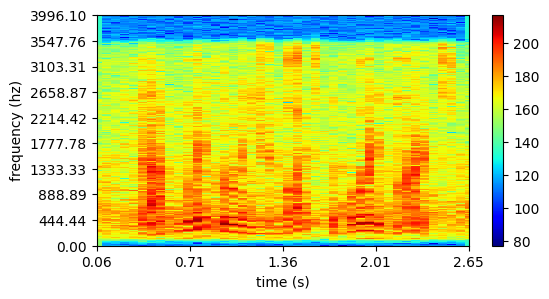

timebins:  42
freqbins:  513


<Figure size 640x480 with 0 Axes>

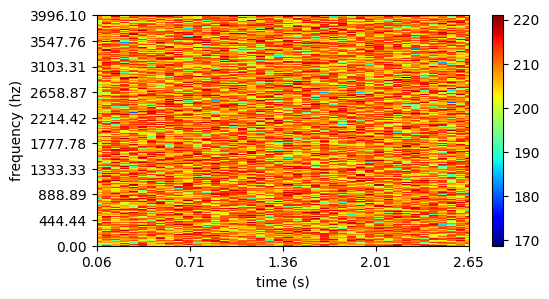

timebins:  42
freqbins:  513


<Figure size 640x480 with 0 Axes>

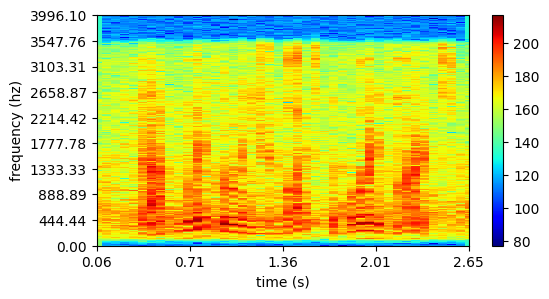

timebins:  42
freqbins:  513


<Figure size 640x480 with 0 Axes>

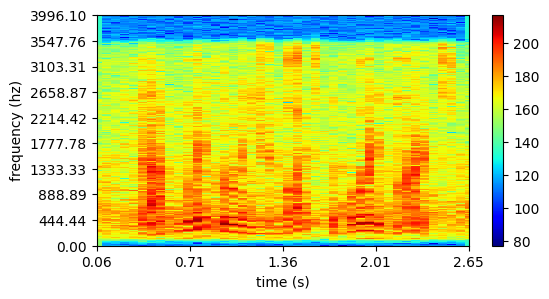

timebins:  43
freqbins:  513


<Figure size 640x480 with 0 Axes>

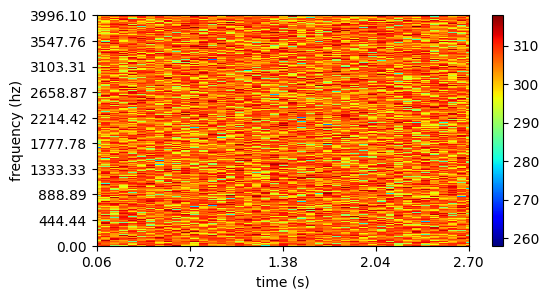

timebins:  43
freqbins:  513


<Figure size 640x480 with 0 Axes>

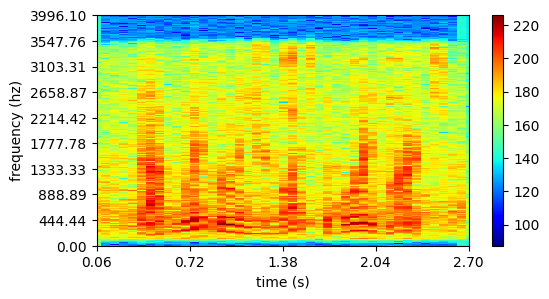

timebins:  42
freqbins:  513


<Figure size 640x480 with 0 Axes>

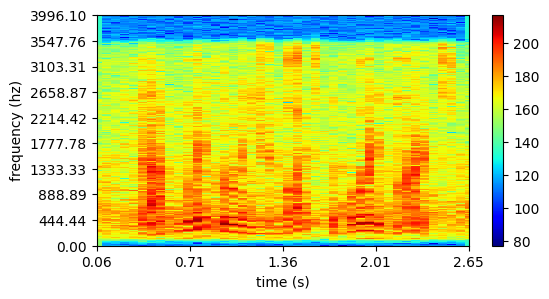

timebins:  42
freqbins:  513


<Figure size 640x480 with 0 Axes>

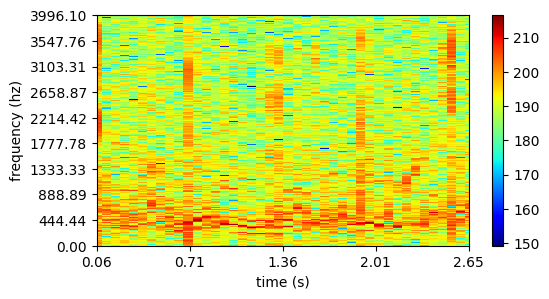

timebins:  42
freqbins:  513


<Figure size 640x480 with 0 Axes>

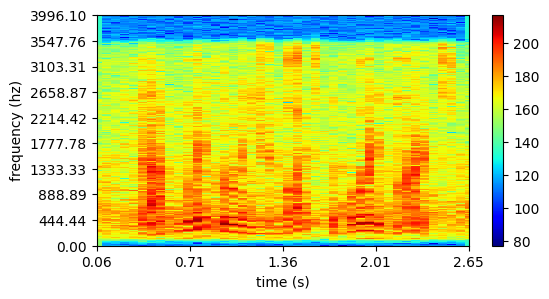

<Figure size 640x480 with 0 Axes>

In [19]:
org_base = ROOT / "dataset" / "test_sounds" / "test_sound"
i = 4
extension = ".wav"
enc_base = ROOT /"test1" / "test_encrypted" / "enc"
dec_base = ROOT /"test1" / "test_decrypted" / "dec"

path = (str(org_base) + str(i) + extension)
ims = spectogram(path)
path = (str(enc_base) + str(i) + extension)
ims = spectogram(path)
path = (str(dec_base) + str(i) + extension)
ims = spectogram(path)



enc_base = ROOT /"test2" / "test_encrypted" / "enc"
dec_base = ROOT /"test2" / "test_decrypted" / "dec"

path = (str(org_base) + str(i) + extension)
ims = spectogram(path)
path = (str(enc_base) + str(i) + extension)
ims = spectogram(path)
path = (str(dec_base) + str(i) + extension)
ims = spectogram(path)




enc_base = ROOT /"test4" / "test_encrypted" / "enc"
dec_base = ROOT /"test4" / "test_decrypted" / "dec"

path = (str(org_base) + str(i) + extension)
ims = spectogram(path)
path = (str(enc_base) + str(i) + extension)
ims = spectogram(path)
path = (str(dec_base) + str(i) + extension)
ims = spectogram(path)

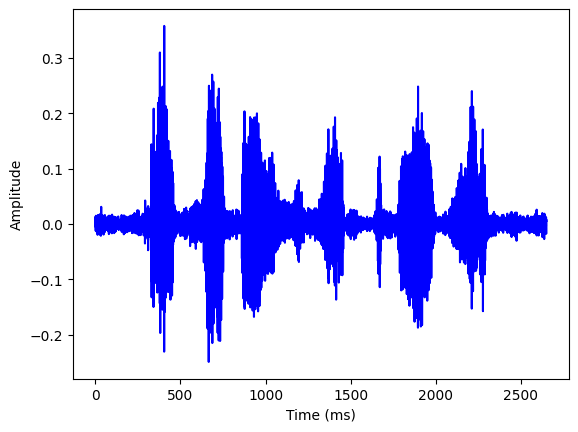

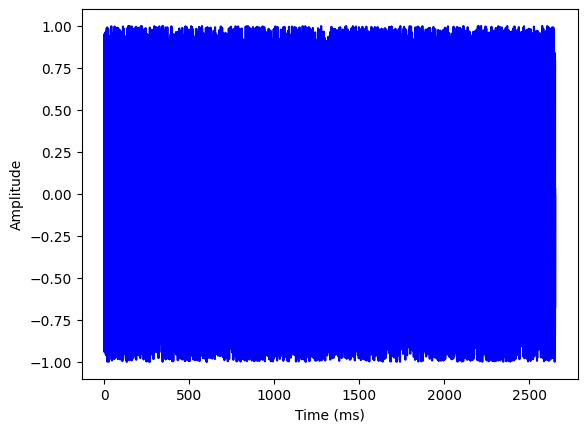

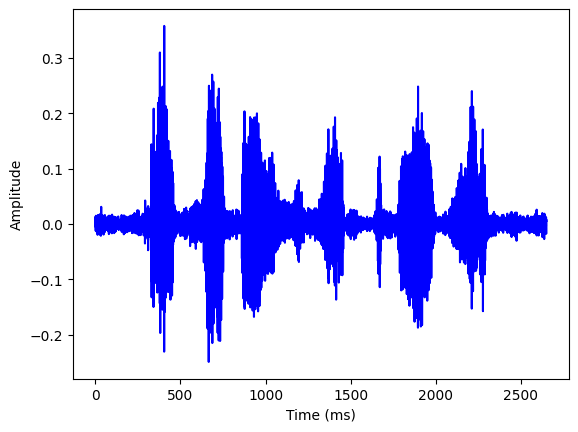

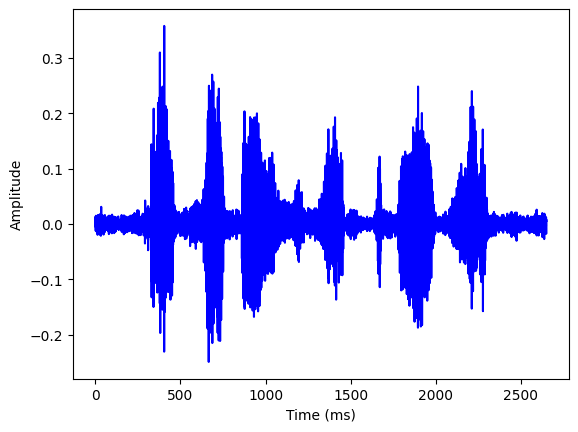

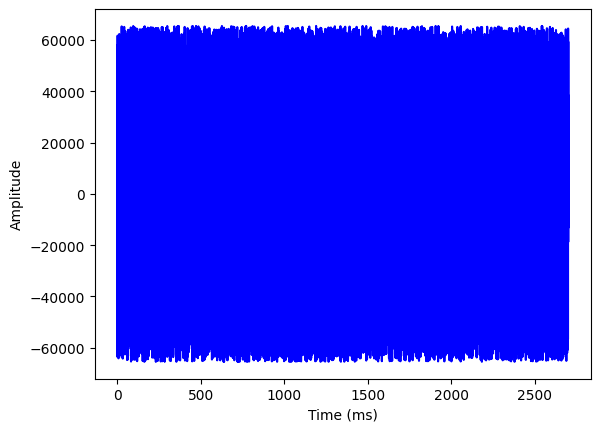

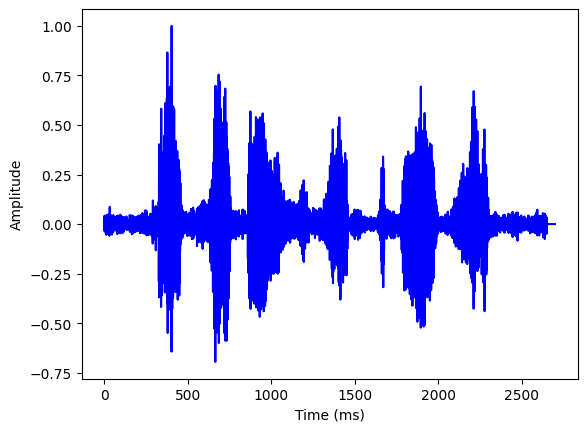

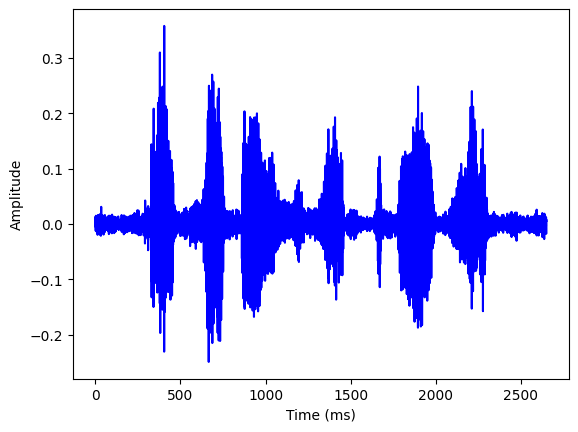

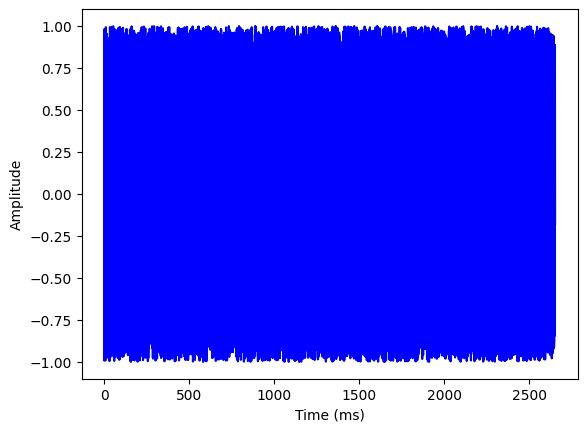

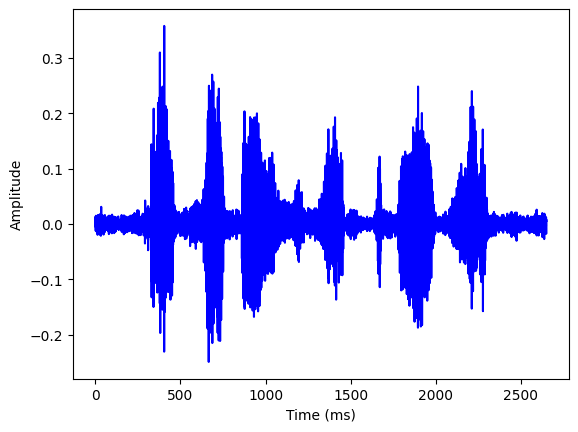

In [82]:
org_base = ROOT / "dataset" / "test_sounds" / "test_sound"
i = 4
extension = ".wav"
enc_base = ROOT /"test1" / "test_encrypted" / "enc"
dec_base = ROOT /"test1" / "test_decrypted" / "dec"

path = (str(org_base) + str(i) + extension)
ims = spectr(path)
path = (str(enc_base) + str(i) + extension)
ims = spectr(path)
path = (str(dec_base) + str(i) + extension)
ims = spectr(path)



enc_base = ROOT /"test2" / "test_encrypted" / "enc"
dec_base = ROOT /"test2" / "test_decrypted" / "dec"

path = (str(org_base) + str(i) + extension)
ims = spectr(path)
path = (str(enc_base) + str(i) + extension)
ims = spectr(path)
path = (str(dec_base) + str(i) + extension)
ims = spectr(path)




enc_base = ROOT /"test4" / "test_encrypted" / "enc"
dec_base = ROOT /"test4" / "test_decrypted" / "dec"

path = (str(org_base) + str(i) + extension)
ims = spectr(path)
path = (str(enc_base) + str(i) + extension)
ims = spectr(path)
path = (str(dec_base) + str(i) + extension)
ims = spectr(path)

## Sensetivity to key changes

test1

In [92]:
extension = ".wav"

org_base = ROOT / "dataset" / "test_sounds" / "test_sound"

i = 1
org = str(org_base.with_name(f"test_sound{i}{extension}"))

x0 = 0.1444
r = 0.9444

enc_base = ROOT / "test1" / "key_change" / "enc"
dec_base = ROOT / "test1" / "key_change" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
test1.script1.test_1_run(org, enc1, dec1, x0, r)

x1 = 0.1443

enc2 = str(enc_base.with_name(f"enc2{extension}"))
dec2 = str(dec_base.with_name(f"dec2{extension}"))
test1.script1.test_1_run(org, enc2, dec2, x1, r)



In [95]:
ber = get_ber(enc1, enc2)
print(ber)

0.5018792828449905


test2


In [97]:
extension = ".wav"

org_base = ROOT / "dataset" / "test_sounds" / "test_sound"

i = 1
org = str(org_base.with_name(f"test_sound{i}{extension}"))

secret1 = 4444
secret2 = 4445
secret3 = 4443

enc_base = ROOT / "test2" / "key_change" / "enc"
dec_base = ROOT / "test2" / "key_change" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
test2.script2.test_2_run(org, enc1, dec1, secret1, secret2, secret3)

secret2 = 4444

enc2 = str(enc_base.with_name(f"enc2{extension}"))
dec2 = str(dec_base.with_name(f"dec2{extension}"))
test2.script2.test_2_run(org, enc2, dec2, secret1, secret2, secret3)



[warn] input rate=8000, orig rate=48000
done
[warn] input rate=8000, orig rate=48000
done


In [98]:
ber = get_ber(enc1, enc2)
print(ber)

0.5024967447916666


test4


In [115]:
extension = ".wav"

org_base = ROOT / "dataset" / "test_sounds" / "test_sound"

i = 1
org = str(org_base.with_name(f"test_sound{i}{extension}"))

seed = 0.012444
r=3.9159

enc_base = ROOT / "test4" / "key_change" / "enc"
dec_base = ROOT / "test4" / "key_change" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
test4.script4.test_4_run(org, enc1, dec1, seed, r, True)

seed = 0.0188883
r=2.456

enc2 = str(enc_base.with_name(f"enc2{extension}"))
dec2 = str(dec_base.with_name(f"dec2{extension}"))
test4.script4.test_4_run(org, enc2, dec2, seed, r, True)



[key] not found, generating: test4/artefacts/key_u8.bin
[key] saved: test4/artefacts/key_u8.bin (10000 bytes)
Key length: 10000
Extract from input audio file
E:\labs\5 course\NearS\measures\dataset\test_sounds\test_sound1.wav
Written to file  E:\labs\5 course\NearS\measures\test4\key_change\enc1.wav
Now we write the values back into a audio file
Written to file  E:\labs\5 course\NearS\measures\test4\key_change\dec1.wav
[key] not found, generating: test4/artefacts/key_u8.bin
[key] saved: test4/artefacts/key_u8.bin (10000 bytes)
Key length: 10000
Extract from input audio file
E:\labs\5 course\NearS\measures\dataset\test_sounds\test_sound1.wav
Written to file  E:\labs\5 course\NearS\measures\test4\key_change\enc2.wav
Now we write the values back into a audio file
Written to file  E:\labs\5 course\NearS\measures\test4\key_change\dec2.wav


In [116]:
ber = get_ber(enc1, enc2)
print(ber)

0.5092930352079396


## Sensetivity to input change

In [130]:
org_base = ROOT / "dataset" / "changes_1_bit" / "test_sound"

i = 1
org = str(org_base.with_name(f"test_sound{i}{extension}"))
org_1bit = str(org_base.with_name(f"test_sound_bit_invert{i}{extension}"))

fs, bytes_1 = load_wav_bytes(org)
bytes_2 = bytes_1.copy()
bytes_2[0] ^= 0b00010000

save_wav_bytes((fs, bytes_2), org_1bit)

test1

In [131]:
extension = ".wav"

org_base = ROOT / "dataset" / "changes_1_bit" / "test_sound"

i = 1
org = str(org_base.with_name(f"test_sound{i}{extension}"))

enc_base = ROOT / "test1" / "bit_invert" / "enc"
dec_base = ROOT / "test1" / "bit_invert" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
test1.script1.test_1_run(org, enc1, dec1)


org = str(org_base.with_name(f"test_sound_bit_invert{i}{extension}"))

enc2 = str(enc_base.with_name(f"enc2{extension}"))
dec2 = str(dec_base.with_name(f"dec2{extension}"))
test1.script1.test_1_run(org, enc2, dec2)



In [132]:
ber = get_ber(enc1, enc2)
print(ber)

3.69210775047259e-06


test2

In [133]:
extension = ".wav"

org_base = ROOT / "dataset" / "changes_1_bit" / "test_sound"

i = 1
org = str(org_base.with_name(f"test_sound{i}{extension}"))

enc_base = ROOT / "test2" / "bit_invert" / "enc"
dec_base = ROOT / "test2" / "bit_invert" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
test2.script2.test_2_run(org, enc1, dec1)


org = str(org_base.with_name(f"test_sound_bit_invert{i}{extension}"))

enc2 = str(enc_base.with_name(f"enc2{extension}"))
dec2 = str(dec_base.with_name(f"dec2{extension}"))
test2.script2.test_2_run(org, enc2, dec2)



[warn] input rate=8000, orig rate=48000
done
[warn] input rate=8000, orig rate=48000
done


In [134]:
ber = get_ber(enc1, enc2)
print(ber)

1.6276041666666666e-05


test4

In [135]:
extension = ".wav"

org_base = ROOT / "dataset" / "changes_1_bit" / "test_sound"

i = 1
org = str(org_base.with_name(f"test_sound{i}{extension}"))

enc_base = ROOT / "test4" / "bit_invert" / "enc"
dec_base = ROOT / "test4" / "bit_invert" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
test4.script4.test_4_run(org, enc1, dec1)


org = str(org_base.with_name(f"test_sound_bit_invert{i}{extension}"))

enc2 = str(enc_base.with_name(f"enc2{extension}"))
dec2 = str(dec_base.with_name(f"dec2{extension}"))
test4.script4.test_4_run(org, enc2, dec2)



[key] loaded: test4/artefacts/key_u8.bin (10000 bytes)
Key length: 10000
Extract from input audio file
E:\labs\5 course\NearS\measures\dataset\changes_1_bit\test_sound1.wav
Written to file  E:\labs\5 course\NearS\measures\test4\bit_invert\enc1.wav
Now we write the values back into a audio file
Written to file  E:\labs\5 course\NearS\measures\test4\bit_invert\dec1.wav
[key] loaded: test4/artefacts/key_u8.bin (10000 bytes)
Key length: 10000
Extract from input audio file
E:\labs\5 course\NearS\measures\dataset\changes_1_bit\test_sound_bit_invert1.wav
Written to file  E:\labs\5 course\NearS\measures\test4\bit_invert\enc2.wav
Now we write the values back into a audio file
Written to file  E:\labs\5 course\NearS\measures\test4\bit_invert\dec2.wav


In [136]:
ber = get_ber(enc1, enc2)
print(ber)

3.69210775047259e-06


### нет лавинного эффекта из-за xor-шифрования (beer~0, при изменении 1 бита на входе, в шифротексте меняется 1 бит as well)

## Пропагация ошибки в шифротексте

In [141]:
i = 1
org_base = ROOT / "dataset" / "chipher_1_bit_error" / "test_sound"
org = str(org_base.with_name(f"test_sound{i}{extension}"))


enc_base = ROOT / "test1" / "chipher_1_bit_error" / "enc"
dec_base = ROOT / "test1" / "chipher_1_bit_error" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
enc2 = str(enc_base.with_name(f"enc_err1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))

test1.script1.test_1_run(org, enc1, dec1, errored_enc=enc2)

ruining


In [ ]:
# сравнение орига и дешифра
ber = get_ber(org, dec1)
print(ber)
# сравнение шифров. если около 0, то всрался 1 бит или очень мало битов
ber = get_ber(enc1, enc2)
print(ber)

3.69210775047259e-06
3.69210775047259e-06


то есть 1 бит всрался в шифре при передаче = 1 бит всрётся при дешифровке. Устойчивость к помехам, получается

test2

In [152]:
i = 1
org_base = ROOT / "dataset" / "chipher_1_bit_error" / "test_sound"
org = str(org_base.with_name(f"test_sound{i}{extension}"))


secret1 = 4444
secret2 = 4445
secret3 = 4443

enc_base = ROOT / "test2" / "chipher_1_bit_error" / "enc"
dec_base = ROOT / "test2" / "chipher_1_bit_error" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
enc2 = str(enc_base.with_name(f"enc_err1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
test2.script2.test_2_run(org, enc1, dec1, secret1, secret2, secret3, errored_enc=enc2)

dec2 = str(dec_base.with_name(f"dec2{extension}"))
test2.script2.test_2_run(org, enc1, dec2, secret1, secret2, secret3)


[warn] input rate=8000, orig rate=48000
done
[warn] input rate=8000, orig rate=48000
done


In [ ]:
# сравнение орига и дешифра. если около 0, то всрался 1 бит или очень мало битов, если 0.3, то треть всралась
ber = get_ber(org, dec1)
print(ber)
# ориг и дешифр БЕЗ внесения ошибки в шифротекст
ber = get_ber(org, dec2)
print(ber)
# дешифр БЕЗ внесения ошибки в шифротекст и дешифр С ВНЕСЕНИЕМ ошибки в шифротекст
ber = get_ber(dec1, dec2)
print(ber)
# сравнение шифров. если около 0, то всрался 1 бит или очень мало битов
ber = get_ber(enc1, enc2)
print(ber)

0.31688622400756145
0.3302922672495274
0.32394856770833336
3.2552083333333335e-06


тут уже посильнее всрался дешифр по сравнению с оригиналом, но мб из-за корреляции 0,7 в начале, мб просто восстанавливает хреноватенько

test4

In [147]:
i = 1
org_base = ROOT / "dataset" / "chipher_1_bit_error" / "test_sound"
org = str(org_base.with_name(f"test_sound{i}{extension}"))


enc_base = ROOT / "test4" / "chipher_1_bit_error" / "enc"
dec_base = ROOT / "test4" / "chipher_1_bit_error" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
enc2 = str(enc_base.with_name(f"enc_err1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))

test4.script4.test_4_run(org, enc1, dec1, errored_enc=enc2)

[key] loaded: test4/artefacts/key_u8.bin (10000 bytes)
Key length: 10000
Extract from input audio file
E:\labs\5 course\NearS\measures\dataset\chipher_1_bit_error\test_sound1.wav
Written to file  E:\labs\5 course\NearS\measures\test4\chipher_1_bit_error\enc1.wav
Now we write the values back into a audio file
Written to file  E:\labs\5 course\NearS\measures\test4\chipher_1_bit_error\dec1.wav


In [148]:
# сравнение орига и дешифра. если около 0, то всрался 1 бит или очень мало битов, если 0.3, то треть всралась
ber = get_ber(org, dec1)
print(ber)
# сравнение шифров. если около 0, то всрался 1 бит или очень мало битов
ber = get_ber(enc1, enc2)
print(ber)

3.69210775047259e-06
3.69210775047259e-06


## ТЕСТ КОВЕРТАЦИИ В ДРУГИЕ ФОРМАТЫ ШИФРОТЕКСТА ПРИ ПЕРЕДАЧЕ

test1

In [165]:
i = 1
org_base = ROOT / "dataset" / "chipher_1_bit_error" / "test_sound"
org = str(org_base.with_name(f"test_sound{i}{extension}"))


enc_base = ROOT / "test1" / "convertations" / "enc"
dec_base = ROOT / "test1" / "convertations" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
org_format = "wav"
new_format = "mp3"

test1.script1.test_1_run(org, enc1, dec1, org_format=org_format, new_format=new_format)
ber = get_ber(org, dec1)
print(ber)

0.4852721821833648


test2

In [ ]:
i = 1
org_base = ROOT / "dataset" / "chipher_1_bit_error" / "test_sound"
org = str(org_base.with_name(f"test_sound{i}{extension}"))


enc_base = ROOT / "test2" / "convertations" / "enc"
dec_base = ROOT / "test2" / "convertations" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
org_format = "wav"
new_format = "mp3"

test2.script2.test_2_run(org, enc1, dec1, org_format=org_format, new_format=new_format)
ber = get_ber(org, dec1)
print(ber)

[warn] input rate=8000, orig rate=48000
done
0.48521680056710775


test4

In [ ]:
i = 1
org_base = ROOT / "dataset" / "chipher_1_bit_error" / "test_sound"
org = str(org_base.with_name(f"test_sound{i}{extension}"))


enc_base = ROOT / "test4" / "convertations" / "enc"
dec_base = ROOT / "test4" / "convertations" / "dec"
enc1 = str(enc_base.with_name(f"enc1{extension}"))
dec1 = str(dec_base.with_name(f"dec1{extension}"))
org_format = "wav"
new_format = "mp3"

test4.script4.test_4_run(org, enc1, dec1, org_format=org_format, new_format=new_format)
ber = get_ber(org, dec1)
print(ber)

[key] loaded: test4/artefacts/key_u8.bin (10000 bytes)
Key length: 10000
Extract from input audio file
E:\labs\5 course\NearS\measures\dataset\chipher_1_bit_error\test_sound1.wav
Written to file  E:\labs\5 course\NearS\measures\test4\convertations\enc1.wav
Now we write the values back into a audio file
Written to file  E:\labs\5 course\NearS\measures\test4\convertations\dec1.wav
0.4043079513232514


ber такой низкий из-за того что mp3 теряет данные при преобразовании в него